# Formula 1 Podium Prediction — Milestone 1

**CSEN 903: Advanced Computer Lab, Winter 2026 — Team 121**

| Member | ID |
|---|---|
| Omar Yasser | 58-1906 |
| Anas Jabr | 58-5506 |
| Omar Elkhayat | 58-9780 |
| Fawzy Kareem | 58-9264 |

Kaggle: https://www.kaggle.com/code/omaryasser102/milestone-1-121-acl · GitHub: https://github.com/Omarryasserr102/ACL2-Team121-F1-M1

In this notebook we predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information that is available **after qualifying and before the race starts**. Each row of our modelling table is one driver entering one race.

**Notebook outline**
1. Setup and data loading
2. Exploratory data analysis (before cleaning)
3. Data audit: primary and foreign keys
4. Data cleaning
5. Exploratory data analysis (after cleaning)
6. Data-engineering questions
7. Feature engineering: the leakage-safe modelling table
8. Dataset splitting
9. Preprocessing-order experiment
10. Model training and evaluation
11. Feature-group ablation
12. Explainability (XAI)
13. Inference function
14. Limitations

## 1. Setup and data loading

`shap` is already available on Kaggle; `lime` has to be installed .

In [1]:
!pip install -q shap lime

In [2]:
import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide TensorFlow's C++ start-up logs
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, accuracy_score,
    precision_score, recall_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

import shap
import lime.lime_tabular

SEED = 121
# seeds Python, NumPy and TensorFlow in one call
keras.utils.set_random_seed(SEED)
# makes the neural network produce the same weights on every run
tf.config.experimental.enable_op_determinism()

sns.set_theme(style='whitegrid')

### Loading the 14 tables

The dataset is attached through Kaggle's **Input** tab. We read every CSV with `keep_default_na=False` so that the literal `\N` placeholders stay visible for the audit. The raw tables are never modified; all cleaning happens on copies.

In [3]:
DATA_DIR = Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020')
if not DATA_DIR.exists():
    # older Kaggle layout: /kaggle/input/<dataset-slug>
    DATA_DIR = Path('/kaggle/input/formula-1-world-championship-1950-2020')
if not DATA_DIR.exists():
    DATA_DIR = next(Path('/kaggle/input').rglob('races.csv')).parent
print('Reading data from:', DATA_DIR)

table_names = ['circuits', 'constructor_results', 'constructor_standings', 'constructors',
               'driver_standings', 'drivers', 'lap_times', 'pit_stops', 'qualifying',
               'races', 'results', 'seasons', 'sprint_results', 'status']

raw = {}
for name in table_names:
    raw[name] = pd.read_csv(DATA_DIR / f'{name}.csv', keep_default_na=False,
                            na_values=[], low_memory=False)

pd.DataFrame({
    'table': table_names,
    'rows': [len(raw[name]) for name in table_names],
    'columns': [raw[name].shape[1] for name in table_names]
})

Reading data from: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


,table,rows,columns
0,circuits,77,9
1,constructor_results,12625,5
2,constructor_standings,13391,7
3,constructors,212,5
4,driver_standings,34863,7
5,drivers,861,9
6,lap_times,589081,6
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18


## 2. Exploratory data analysis (before cleaning)

We first look at every table exactly as it was loaded. This tells us the column types, which columns contain placeholders, and where the data is thin.

In [4]:
for name, df in raw.items():
    print(f'===== {name} {df.shape} =====')
    df.info()
    print()

===== circuits (77, 9) =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

===== constructor_results (12625, 5) =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  


In [5]:
raw['results'].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [6]:
raw['results'].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
resultId,26759.0,NaN,NaN,NaN,13380.977391,7726.134642,1.0,6690.5,13380.0,20069.5,26764.0
raceId,26759.0,NaN,NaN,NaN,551.687283,313.265036,1.0,300.0,531.0,811.0,1144.0
driverId,26759.0,NaN,NaN,NaN,278.67353,282.703039,1.0,57.0,172.0,399.5,862.0
constructorId,26759.0,NaN,NaN,NaN,50.180537,61.551498,1.0,6.0,25.0,63.0,215.0
number,26759,130,4,1019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
grid,26759.0,NaN,NaN,NaN,11.134796,7.20286,0.0,5.0,11.0,17.0,34.0
position,26759,34,\N,10953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionText,26759,39,R,8897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positionOrder,26759.0,NaN,NaN,NaN,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,NaN,NaN,NaN,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0


In [7]:
raw['qualifying'].head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


### Sentinel values

`pandas` does not recognise `\N` as missing, so `isnull()` reports zero missing values everywhere. We count the sentinels ourselves, column by column.

In [8]:
sentinel_rows = []
for name, df in raw.items():
    for col in df.columns:
        count = (df[col].astype(str) == '\\N').sum()
        if count > 0:
            sentinel_rows.append((name, col, count))

sentinels = pd.DataFrame(sentinel_rows, columns=['table', 'column', 'sentinel_count'])
sentinels.sort_values('sentinel_count', ascending=False)

,table,column,sentinel_count
19,results,time,19079
20,results,milliseconds,19079
23,results,fastestLapTime,18507
21,results,fastestLap,18507
24,results,fastestLapSpeed,18507
22,results,rank,18249
0,constructor_results,status,12608
18,results,position,10953
5,qualifying,q3,6819
4,qualifying,q2,4625


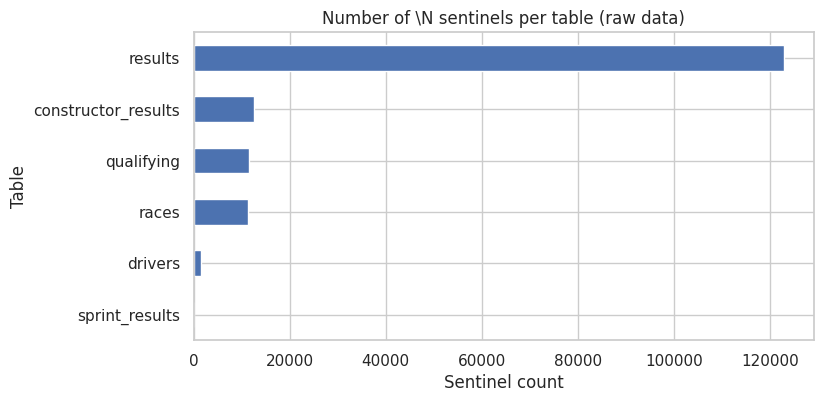

In [9]:
sentinels_per_table = sentinels.groupby('table')['sentinel_count'].sum().sort_values()

sentinels_per_table.plot(kind='barh', figsize=(8, 4))
plt.title('Number of \\N sentinels per table (raw data)')
plt.xlabel('Sentinel count')
plt.ylabel('Table')
plt.show()

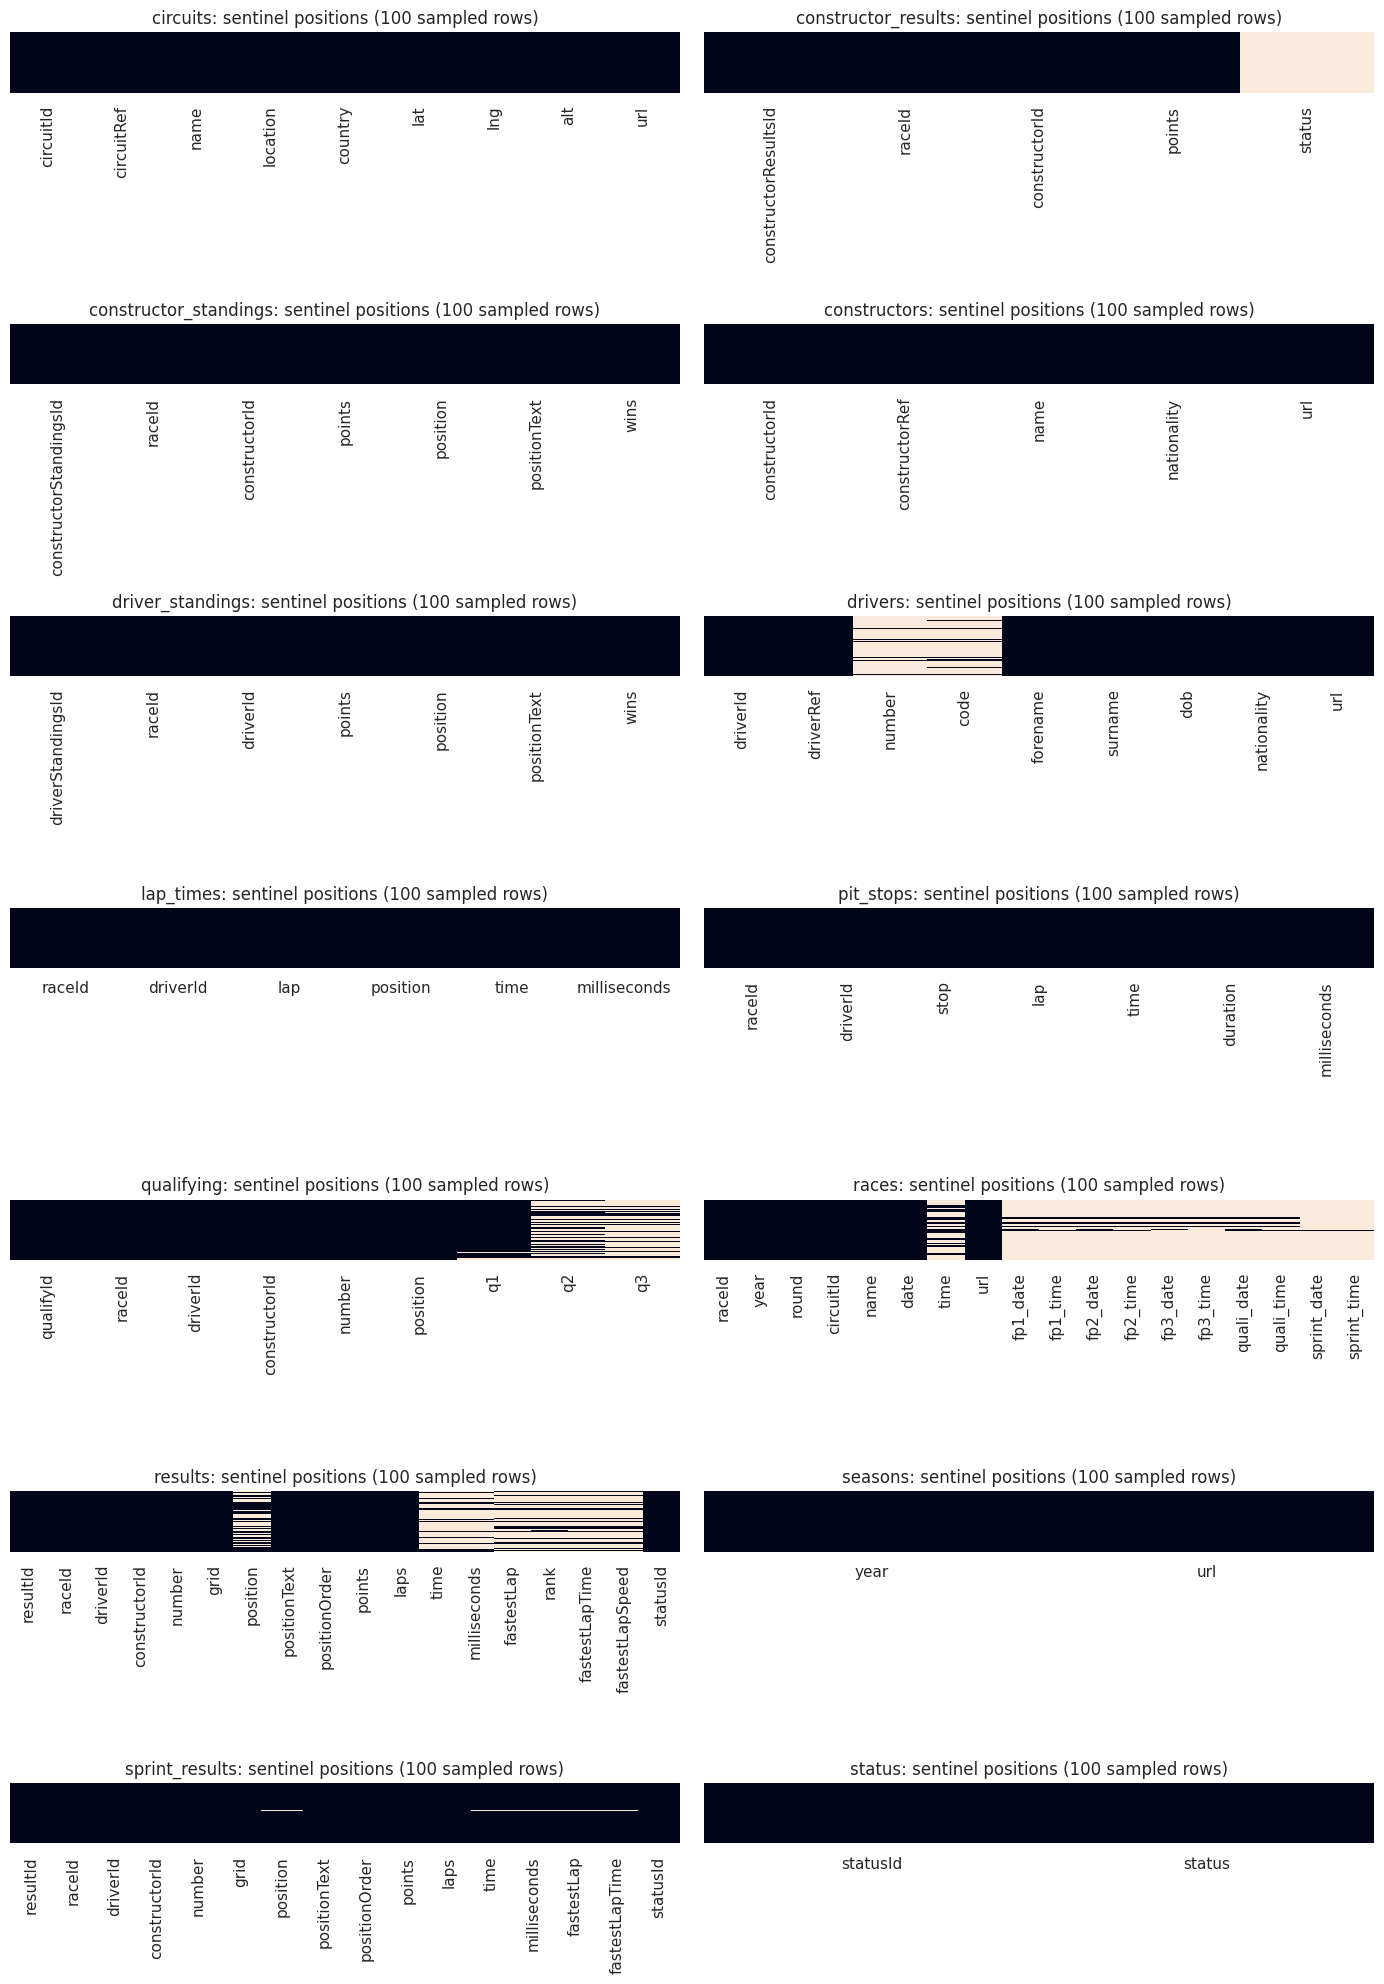

In [10]:
fig, axes = plt.subplots(7, 2, figsize=(14, 20))

for ax, (name, df) in zip(axes.flat, raw.items()):
    sample = df.sample(min(100, len(df)), random_state=SEED)
    sns.heatmap(sample.astype(str) == '\\N', cbar=False, yticklabels=False, ax=ax)
    ax.set_title(f'{name}: sentinel positions (100 sampled rows)')

plt.tight_layout()
plt.show()

### Target, coverage and field size

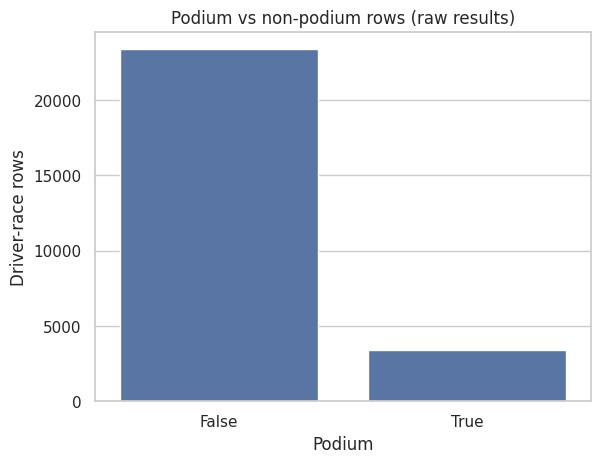

Podium share: 0.1269


In [11]:
raw_podium = pd.to_numeric(raw['results']['positionOrder']) <= 3

sns.countplot(x=raw_podium)
plt.title('Podium vs non-podium rows (raw results)')
plt.xlabel('Podium')
plt.ylabel('Driver-race rows')
plt.show()

print('Podium share:', round(raw_podium.mean(), 4))

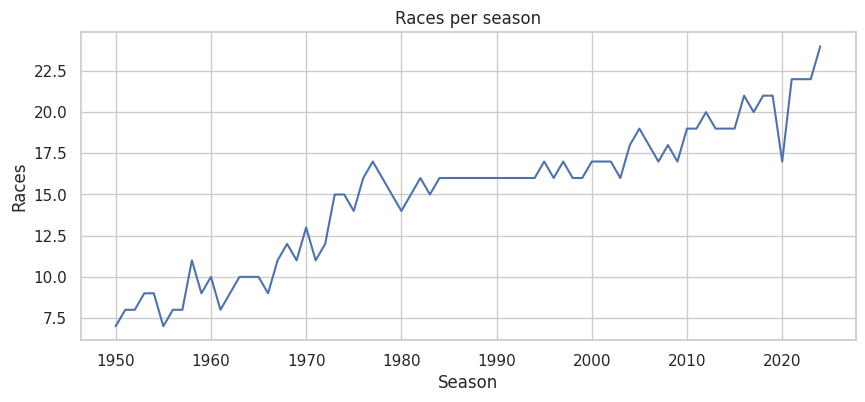

In [12]:
races_per_season = raw['races'].groupby('year').size()

races_per_season.plot(figsize=(10, 4))
plt.title('Races per season')
plt.xlabel('Season')
plt.ylabel('Races')
plt.show()

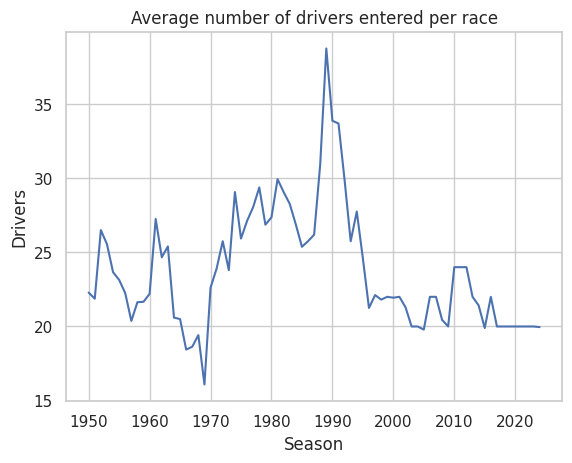

In [13]:
drivers_per_race = (raw['results'].groupby('raceId')['driverId'].nunique()
                    .rename('drivers').reset_index()
                    .merge(raw['races'][['raceId', 'year']], on='raceId'))

sns.lineplot(data=drivers_per_race, x='year', y='drivers', errorbar=None)
plt.title('Average number of drivers entered per race')
plt.xlabel('Season')
plt.ylabel('Drivers')
plt.show()

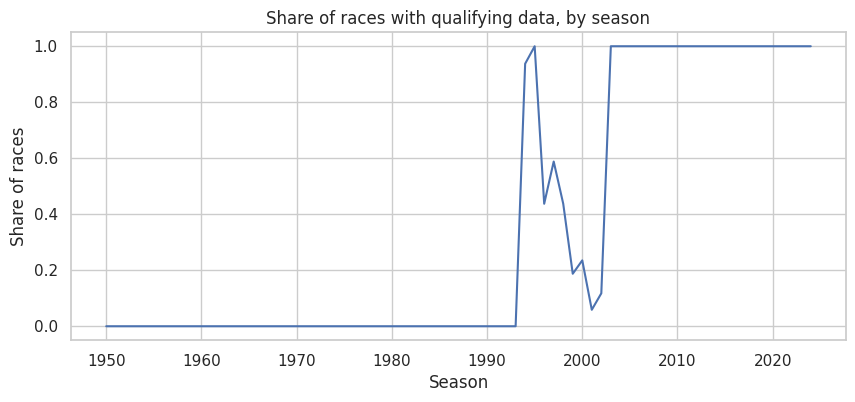

In [14]:
races_with_quali = raw['qualifying']['raceId'].unique()
quali_coverage = (raw['races']
                  .assign(has_qualifying=raw['races']['raceId'].isin(races_with_quali))
                  .groupby('year')['has_qualifying'].mean())

quali_coverage.plot(figsize=(10, 4))
plt.title('Share of races with qualifying data, by season')
plt.xlabel('Season')
plt.ylabel('Share of races')
plt.show()

**Observations before cleaning**
- The `results` table has 26,759 rows and about 12.7% of them are podiums, so the positive class is the minority.
- `results` carries most of the `\N` sentinels: `time`, `milliseconds` and the fastest-lap fields are only recorded for some finishers and for recent seasons.
- In `qualifying`, `q2` and `q3` are missing by design, because only the drivers who advance set a Q2/Q3 time.
- Qualifying data does not exist before 1994 and is patchy until 2002; only from 2003 does every race have it. Most historical races therefore have a starting grid but no qualifying record. This is why we keep `grid` as the main starting-position feature and treat qualifying features as optional, with missing-value indicators.
- Field sizes were much larger and more irregular in the early decades, which changes how hard a podium is from era to era.

## 3. Data audit: primary and foreign keys

Before joining tables we verify that every primary key is unique and non-null, and that every foreign key points to a record that exists in its parent table.

In [15]:
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'],
    'constructor_results': ['constructorResultsId'], 'constructor_standings': ['constructorStandingsId'],
    'drivers': ['driverId'], 'driver_standings': ['driverStandingsId'], 'races': ['raceId'],
    'results': ['resultId'], 'qualifying': ['qualifyId'], 'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'], 'sprint_results': ['resultId'],
    'seasons': ['year'], 'status': ['statusId']
}

pk_audit = []
for table, key in primary_keys.items():
    df = raw[table]
    null_keys = (df[key].astype(str) == '\\N').any(axis=1).sum()
    duplicate_keys = df.duplicated(key).sum()
    pk_audit.append((table, ', '.join(key), null_keys, duplicate_keys))

pd.DataFrame(pk_audit, columns=['table', 'primary key', 'null keys', 'duplicate keys'])

,table,primary key,null keys,duplicate keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


In [16]:
foreign_keys = {'raceId': 'races', 'driverId': 'drivers', 'constructorId': 'constructors',
                'circuitId': 'circuits', 'statusId': 'status'}

fk_audit = []
for child, df in raw.items():
    for key, parent in foreign_keys.items():
        if key in df.columns and child != parent:
            parent_ids = set(raw[parent][key].astype(str))
            unmatched = (~df[key].astype(str).isin(parent_ids)).sum()
            fk_audit.append((child, key, parent, unmatched))

pd.DataFrame(fk_audit, columns=['child table', 'foreign key', 'parent table', 'unmatched rows'])

,child table,foreign key,parent table,unmatched rows
0,constructor_results,raceId,races,0
1,constructor_results,constructorId,constructors,0
2,constructor_standings,raceId,races,0
3,constructor_standings,constructorId,constructors,0
4,driver_standings,raceId,races,0
5,driver_standings,driverId,drivers,0
6,lap_times,raceId,races,0
7,lap_times,driverId,drivers,0
8,pit_stops,raceId,races,0
9,pit_stops,driverId,drivers,0


### Duplicate driver-race rows (shared drives)

Our unit of analysis is one driver in one race, so `(raceId, driverId)` must be unique. In the 1950s drivers sometimes swapped cars mid-race, which produces more than one result row for the same driver in the same race.

In [17]:
shared = raw['results'].duplicated(['raceId', 'driverId'], keep=False)
shared_pairs = raw['results'].loc[shared, ['raceId', 'driverId']].drop_duplicates()

print('Result rows involved in shared drives:', shared.sum())
print('Affected driver-race pairs:', len(shared_pairs))

raw['results'].loc[shared, ['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'laps']].head(6)

Result rows involved in shared drives: 176
Affected driver-race pairs: 85


,raceId,driverId,constructorId,grid,positionOrder,laps
13188,540,229,54,0,26,0
13191,540,229,57,0,29,0
17362,717,373,172,1,7,102
17740,733,465,172,0,22,0
17743,733,465,97,0,25,0
17961,742,475,102,20,19,56


**Audit result:** all 14 primary keys are unique and non-null, and every foreign key reconciles with its parent table (0 unmatched rows). The only grain problem is the shared drives in `results`, which we resolve during cleaning.

## 4. Data cleaning

### 4.1 Sentinels to `NaN`

We work on a copy of every table and replace `\N` with a real missing value.

In [18]:
clean = {name: df.replace('\\N', np.nan) for name, df in raw.items()}

### 4.2 Semantic typing

Dates become `datetime` objects, lap-time strings such as `1:27.452` become numeric seconds, and the result and qualifying columns that held sentinels become numeric.

In [19]:
clean['races']['date'] = pd.to_datetime(clean['races']['date'])
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'])

In [20]:
def time_to_seconds(series):
    """Convert lap-time strings like '1:27.452' or '58.123' to seconds."""
    parts = series.astype(str).str.extract(r'^(?:(\d+):)?(\d+\.\d+)$')
    minutes = pd.to_numeric(parts[0], errors='coerce').fillna(0)
    seconds = pd.to_numeric(parts[1], errors='coerce')
    return minutes * 60 + seconds


for col in ['q1', 'q2', 'q3']:
    clean['qualifying'][f'{col}_seconds'] = time_to_seconds(clean['qualifying'][col])
clean['results']['fastestLapTime_seconds'] = time_to_seconds(clean['results']['fastestLapTime'])
clean['lap_times']['time_seconds'] = time_to_seconds(clean['lap_times']['time'])
clean['pit_stops']['duration_seconds'] = time_to_seconds(clean['pit_stops']['duration'])

clean['qualifying'][['q1', 'q1_seconds', 'q2', 'q2_seconds', 'q3', 'q3_seconds']].head()

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


In [21]:
result_numeric = ['resultId', 'raceId', 'driverId', 'constructorId', 'grid', 'position',
                  'positionOrder', 'points', 'laps', 'milliseconds', 'statusId']
for col in result_numeric:
    clean['results'][col] = pd.to_numeric(clean['results'][col])

clean['qualifying']['position'] = pd.to_numeric(clean['qualifying']['position'])

clean['results'].dtypes

resultId                    int64
raceId                      int64
driverId                    int64
constructorId               int64
number                     object
grid                        int64
position                  float64
positionText               object
positionOrder               int64
points                    float64
laps                        int64
time                       object
milliseconds              float64
fastestLap                 object
rank                       object
fastestLapTime             object
fastestLapSpeed            object
statusId                    int64
fastestLapTime_seconds    float64
dtype: object

### 4.3 Fixing the grain: one row per `(raceId, driverId)`

**Rule for shared drives:** keep the row of the car the driver *started* in (`grid > 0`); if that still leaves more than one row, keep the better final position; if there is still a tie, keep the lower `resultId` so the result is the same on every run.

We chose this rule because our features describe the driver's starting situation (grid slot, qualifying, form coming into the race), and that information belongs to the car the driver started in. The target then has exactly one value per driver-race.

In [22]:
results = clean['results'].copy()
rows_before = len(results)

results['started'] = results['grid'] > 0
results = results.sort_values(['raceId', 'driverId', 'started', 'positionOrder', 'resultId'],
                              ascending=[True, True, False, True, True])
results = results.drop_duplicates(['raceId', 'driverId']).drop(columns='started')

assert not results.duplicated(['raceId', 'driverId']).any()
print('Rows before:', rows_before, '| after:', len(results), '| removed:', rows_before - len(results))

Rows before: 26759 | after: 26668 | removed: 91


### 4.4 Which fields are "future" information?

Our prediction cutoff is *after qualifying, before the race starts*. Anything recorded during or after the race would be data leakage if used as a feature.

| Field / table | Known before the race? | Use |
|---|---|---|
| `results.grid` | Yes, set after qualifying and penalties | feature |
| `qualifying.position`, `q1`–`q3` | Yes | feature |
| `results.positionOrder` | No | **target only** |
| `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap*`, `rank`, `statusId` | No | excluded |
| `lap_times`, `pit_stops` | No, recorded during the race | excluded |
| `driver_standings`, `constructor_standings` of the current race | No, updated after the race | excluded (we build our own form features from earlier races) |
| `sprint_results` | Depends on the season's weekend format; only 2021+ | excluded: too few rows and an inconsistent cutoff |

## 5. Exploratory data analysis (after cleaning)

Now we check the effect of cleaning. If the conversion is correct, every sentinel should become exactly one `NaN` in the original columns.

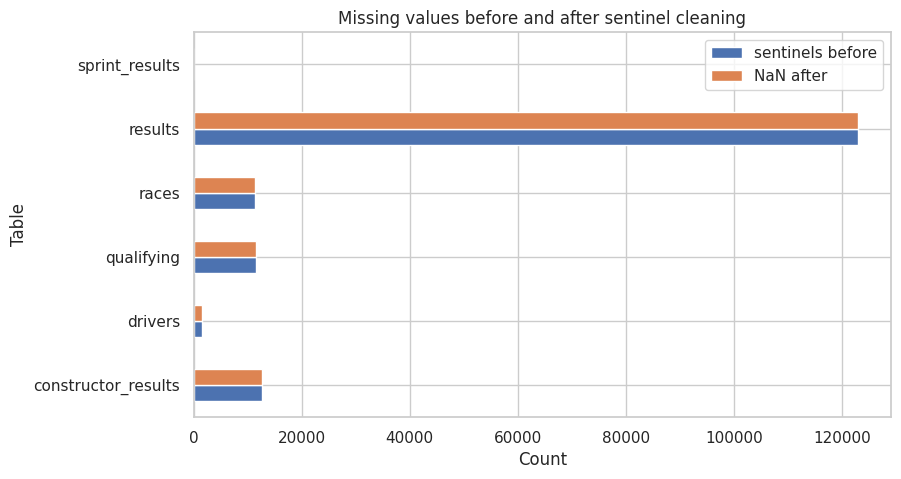

,sentinels before,NaN after
constructor_results,12608.0,12608
drivers,1559.0,1559
qualifying,11600.0,11600
races,11349.0,11349
results,122887.0,122887
sprint_results,73.0,73


In [23]:
nan_after = pd.Series({name: df[raw[name].columns].isna().sum().sum() for name, df in clean.items()})
cleaning_check = pd.DataFrame({
    'sentinels before': sentinels_per_table,
    'NaN after': nan_after
}).fillna(0)
cleaning_check = cleaning_check[cleaning_check.sum(axis=1) > 0]

cleaning_check.plot(kind='barh', figsize=(9, 5))
plt.title('Missing values before and after sentinel cleaning')
plt.xlabel('Count')
plt.ylabel('Table')
plt.show()

cleaning_check

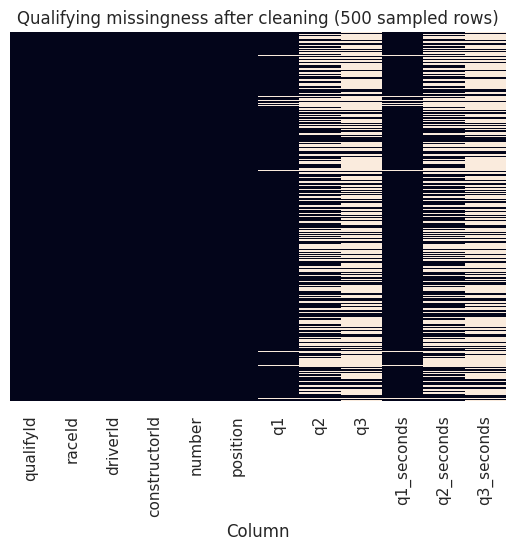

Share of races with qualifying data: 0.439


In [24]:
sns.heatmap(clean['qualifying'].isna().sample(500, random_state=SEED), cbar=False, yticklabels=False)
plt.title('Qualifying missingness after cleaning (500 sampled rows)')
plt.xlabel('Column')
plt.show()

print('Share of races with qualifying data:',
      round(clean['qualifying']['raceId'].nunique() / clean['races']['raceId'].nunique(), 3))

In [25]:
print('Result rows after fixing the grain:', len(results))
print('Podium share after fixing the grain:', round((results['positionOrder'] <= 3).mean(), 4))
print('Rows with grid = 0 (did not start from a grid slot):', (results['grid'] == 0).sum())

results['positionText'].value_counts().head(10)

Result rows after fixing the grain: 26668
Podium share after fixing the grain: 0.1273
Rows with grid = 0 (did not start from a grid slot): 1635


positionText
R    8819
F    1366
4    1134
3    1133
2    1133
5    1131
1    1128
6    1124
7    1103
8    1075
Name: count, dtype: int64

**Observations after cleaning**
- The sentinel counts and the new `NaN` counts match for every table, so the conversion lost or invented nothing.
- Removing the 91 duplicate shared-drive rows leaves exactly one row per driver-race.
- `grid = 0` marks drivers who did not take the start from a grid slot (non-starters, failed qualifiers and pit-lane starters). `positionText` values `F`, `W` and `E` mark drivers who failed to qualify, withdrew or were excluded. These rows matter when we define the modelling population in Section 7.

## 6. Data-engineering questions

Each answer needs a multi-hop join. These questions describe *completed* races, so they are allowed to use final results and status. None of those fields is used as a model feature. Every join below keeps the `(raceId, driverId)` grain we fixed in Section 4.

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after the 2014 hybrid era?

**Join path:** `results` → `races` (season, circuit) → `circuits` (name), plus `qualifying` (qualifying position).

The starting grid and the qualifying position are not the same thing: grid penalties can move a driver back after qualifying. We use the **grid** for the main ranking, because it is available for every season, and then compare it against the qualifying position for the seasons where both exist.

In [26]:
q1 = (results[['raceId', 'driverId', 'grid', 'positionOrder']]
      .merge(clean['races'][['raceId', 'year', 'circuitId']], on='raceId', validate='many_to_one')
      .merge(clean['circuits'][['circuitId', 'name']], on='circuitId', validate='many_to_one')
      .merge(clean['qualifying'][['raceId', 'driverId', 'position']]
             .rename(columns={'position': 'quali_position'}),
             on=['raceId', 'driverId'], how='left', validate='one_to_one'))

q1['era'] = np.where(q1['year'] >= 2014, '2014+', 'pre-2014')
q1['podium'] = q1['positionOrder'] <= 3
q1.head()

,raceId,driverId,grid,positionOrder,year,circuitId,name,quali_position,era,podium
0,1,1,18,20,2009,1,Albert Park Grand Prix Circuit,15.0,pre-2014,False
1,1,2,9,10,2009,1,Albert Park Grand Prix Circuit,11.0,pre-2014,False
2,1,3,5,6,2009,1,Albert Park Grand Prix Circuit,5.0,pre-2014,False
3,1,4,10,5,2009,1,Albert Park Grand Prix Circuit,12.0,pre-2014,False
4,1,5,12,19,2009,1,Albert Park Grand Prix Circuit,14.0,pre-2014,False


In [27]:
front_row = q1[q1['grid'].between(1, 2)]
conversion = front_row.groupby(['name', 'era'])['podium'].agg(['mean', 'size']).reset_index()

# only circuits with at least 10 front-row starts in BOTH eras, so the rates are comparable
starts = conversion.pivot(index='name', columns='era', values='size').fillna(0)
eligible = starts[starts.min(axis=1) >= 10].index

ranked = conversion[conversion['name'].isin(eligible)].pivot(index='name', columns='era', values='mean')
ranked['change'] = ranked['2014+'] - ranked['pre-2014']
ranked['rank pre-2014'] = ranked['pre-2014'].rank(ascending=False, method='min').astype(int)
ranked['rank 2014+'] = ranked['2014+'].rank(ascending=False, method='min').astype(int)

print('Front-row grid starts analysed:', len(front_row), '| eligible circuits:', len(eligible))
ranked.sort_values('2014+', ascending=False).round(3)

Front-row grid starts analysed: 2243 | eligible circuits: 16


era,2014+,pre-2014,change,rank pre-2014,rank 2014+
name,,,,,
Suzuka Circuit,0.889,0.700,0.189,1,1
Yas Marina Circuit,0.864,0.600,0.264,6,2
Circuit de Monaco,0.850,0.492,0.358,15,3
Circuit de Barcelona-Catalunya,0.818,0.652,0.166,4,4
Circuit de Spa-Francorchamps,0.818,0.551,0.268,12,4
Autódromo José Carlos Pace,0.789,0.597,0.193,8,6
Shanghai International Circuit,0.786,0.650,0.136,5,7
Circuit Gilles Villeneuve,0.778,0.529,0.248,13,8
Silverstone Circuit,0.750,0.564,0.186,10,9


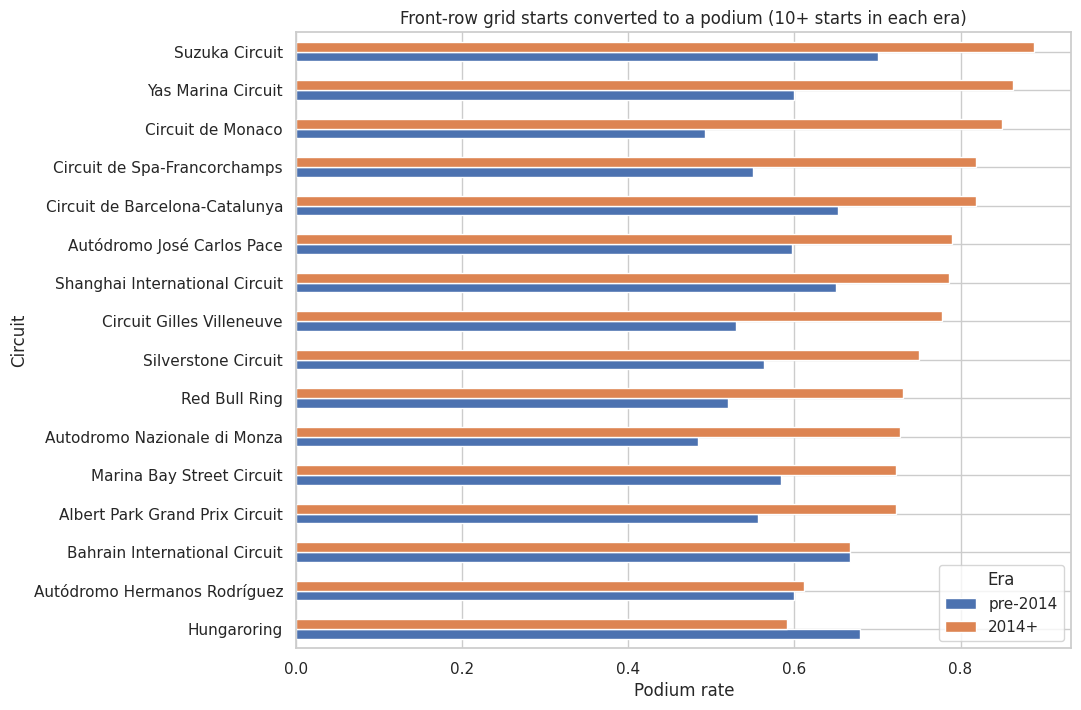

In [28]:
ranked[['pre-2014', '2014+']].sort_values('2014+').plot(kind='barh', figsize=(10, 8))
plt.title('Front-row grid starts converted to a podium (10+ starts in each era)')
plt.xlabel('Podium rate')
plt.ylabel('Circuit')
plt.legend(title='Era')
plt.show()

In [29]:
# grid vs qualifying position, for the rows where both are recorded
both = q1.dropna(subset=['quali_position'])
print('Rows with both a grid slot and a qualifying position:', len(both))
print('Rows where the grid differs from the qualifying position:', (both['grid'] != both['quali_position']).sum())

pd.DataFrame({
    'front row by grid': both[both['grid'].between(1, 2)].groupby('era')['podium'].mean(),
    'front row by qualifying': both[both['quali_position'].between(1, 2)].groupby('era')['podium'].mean(),
    'starts (qualifying)': both[both['quali_position'].between(1, 2)].groupby('era').size()
}).round(3)

Rows with both a grid slot and a qualifying position: 10494
Rows where the grid differs from the qualifying position: 2509


,front row by grid,front row by qualifying,starts (qualifying)
era,,,
2014+,0.760,0.737,456
pre-2014,0.652,0.647,532


**Answer Q1.** Among the 16 circuits with at least 10 front-row starts in both eras, **Suzuka** converts a front-row start into a podium most often, both before 2014 (70%) and from 2014 onwards (89%). Below the top spot the ranking changes a lot after the hybrid era:
- **Monaco** climbs from 15th (49%) to 3rd (85%), and **Spa**, **Monza** and **Circuit Gilles Villeneuve** also gain roughly 24–27 percentage points.
- The **Hungaroring** drops from 2nd (68%) to last (59%); it is the only eligible circuit whose conversion rate fell, and Bahrain stayed flat at 67%.

Overall, front-row starters convert more often after 2014 (76% vs 65% by grid), which is consistent with the long spells of single-team dominance in the hybrid era.

**Grid vs qualifying:** grid and qualifying position differ for many rows (penalties, back-of-grid starts, and grid 0 for pit-lane starters). Measured by qualifying position, front-row conversion also rises after 2014 (about 65% → 74%). Qualifying records only exist from the mid-1990s, so the per-circuit ranking uses the grid.

*Grain:* one row per driver-race after shared-drive handling. *Missingness:* qualifying position is missing for most pre-1994 rows, which is why it is reported separately.

### Q2. Do drivers podium more often at their home circuit, after controlling for starting position?

**Join path:** `results` → `races` → `circuits` (country), and `results` → `drivers` (nationality).

Nationality ("British") and circuit country ("UK") are written differently, so we map one onto the other with an explicit dictionary and report every nationality we could not map. To control for starting position, we compare home and away drivers **within the same grid band**, then average the differences using the size of each band as the weight.

In [30]:
COUNTRY = {
    'British': 'UK', 'Dutch': 'Netherlands', 'German': 'Germany', 'French': 'France',
    'Italian': 'Italy', 'Spanish': 'Spain', 'Brazilian': 'Brazil', 'Australian': 'Australia',
    'Austrian': 'Austria', 'American': 'USA', 'Canadian': 'Canada', 'Mexican': 'Mexico',
    'Belgian': 'Belgium', 'Finnish': 'Finland', 'Japanese': 'Japan', 'Swiss': 'Switzerland',
    'Swedish': 'Sweden', 'Argentine': 'Argentina', 'Argentinian': 'Argentina',
    'Monegasque': 'Monaco', 'Danish': 'Denmark', 'Russian': 'Russia',
    'New Zealander': 'New Zealand', 'South African': 'South Africa', 'Portuguese': 'Portugal',
    'Hungarian': 'Hungary', 'Indian': 'India', 'Chinese': 'China', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Venezuelan': 'Venezuela', 'Colombian': 'Colombia', 'Malaysian': 'Malaysia'
}

home = (results[['raceId', 'driverId', 'grid', 'positionOrder']]
        .merge(clean['races'][['raceId', 'circuitId', 'year']], on='raceId', validate='many_to_one')
        .merge(clean['circuits'][['circuitId', 'country']], on='circuitId', validate='many_to_one')
        .merge(clean['drivers'][['driverId', 'nationality']], on='driverId', validate='many_to_one'))

home['home_country'] = home['nationality'].str.strip().map(COUNTRY)

print('Nationalities we could not map (excluded from this question):')
home.loc[home['home_country'].isna(), 'nationality'].value_counts()

Nationalities we could not map (excluded from this question):


nationality
Irish                92
Chilean              37
Rhodesian            18
Liechtensteiner      13
Indonesian           12
Uruguayan             7
East German           5
Czech                 3
American-Italian      2
Argentine-Italian     2
Name: count, dtype: int64

In [31]:
home = home[home['home_country'].notna() & (home['grid'] > 0)].copy()
home['is_home'] = home['home_country'] == home['country']
home['podium'] = home['positionOrder'] <= 3
home['grid_band'] = pd.cut(home['grid'], bins=[0, 2, 5, 10, 20, 100],
                           labels=['1-2', '3-5', '6-10', '11-20', '21+'])

by_band = home.groupby(['grid_band', 'is_home'], observed=True)['podium'].agg(['mean', 'size']).reset_index()
by_band.round(3)

,grid_band,is_home,mean,size
0,1-2,False,0.605,2064
1,1-2,True,0.553,179
2,3-5,False,0.349,3123
3,3-5,True,0.389,252
4,6-10,False,0.113,5143
5,6-10,True,0.096,480
6,11-20,False,0.020,9796
7,11-20,True,0.020,967
8,21+,False,0.005,2446
9,21+,True,0.009,438


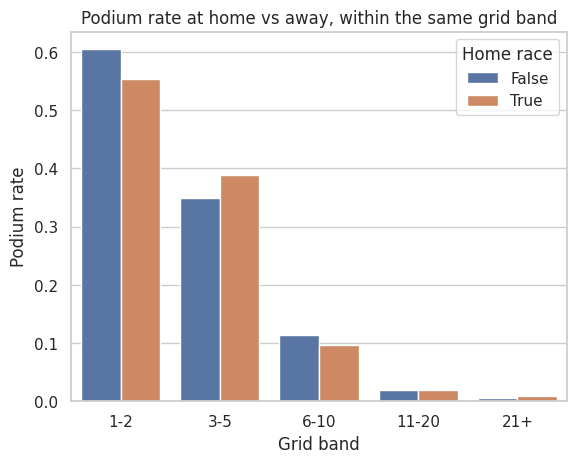

In [32]:
sns.barplot(data=by_band, x='grid_band', y='mean', hue='is_home')
plt.title('Podium rate at home vs away, within the same grid band')
plt.xlabel('Grid band')
plt.ylabel('Podium rate')
plt.legend(title='Home race')
plt.show()

In [33]:
band_weights = home.groupby('grid_band', observed=True).size()
band_weights = band_weights / band_weights.sum()

rates = by_band.pivot(index='grid_band', columns='is_home', values='mean').dropna()
home_effect = np.average(rates[True] - rates[False], weights=band_weights.loc[rates.index])

print(f'Grid-adjusted home minus away podium rate: {home_effect * 100:+.2f} percentage points')

Grid-adjusted home minus away podium rate: -0.28 percentage points


**Answer Q2.** No, we find no home advantage once starting position is controlled for. After weighting the within-band differences, the home-minus-away podium rate is essentially zero (about −0.3 percentage points in our run). The sign also flips between bands: home drivers do slightly worse from the front row and slightly better from P3–P5, which is what noise looks like rather than a consistent effect.

*Caveats:* the home samples are small in the front bands (under 200 home front-row starts), grid bands do not remove every driver or team difference, and drivers whose nationality could not be mapped are excluded. *Grain:* one row per driver-race; only drivers who started from a grid slot are counted.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Join path:** `results` → `status` (reason) → `constructors` (team name), plus `races` (season).

A mechanical retirement is a race start that ended because a car component failed. It excludes crashes, driver-related reasons and regulation decisions. `status` only stores a text reason, so we classify it with an explicit list of component keywords. The denominator is **race starts** (`grid > 0`), not entries.

In [34]:
mechanical_terms = ['Engine', 'Gearbox', 'Transmission', 'Hydraulics', 'Electrical', 'Electronics',
                    'Brake', 'Clutch', 'Suspension', 'Differential', 'Power Unit', 'Turbo', 'Water',
                    'Oil', 'Fuel', 'Radiator', 'Cooling', 'Exhaust', 'Battery', 'ERS', 'MGU',
                    'Alternator', 'Driveshaft', 'Drivetrain', 'Pneumatics', 'Wheel bearing',
                    'Mechanical', 'Overheating', 'Throttle', 'Steering', 'Power loss', 'Halfshaft',
                    'Spark plugs', 'Ignition', 'Injection', 'Magneto', 'Axle', 'CV joint',
                    'Crankshaft', 'Distributor', 'Supercharger', 'Technical', 'Track rod',
                    'Launch control']
# matched by keyword but not a failure of the car itself
not_mechanical = ['Out of fuel', 'Refuelling', 'Fuel rig']

status = clean['status'].copy()
status['mechanical'] = status['status'].apply(
    lambda s: any(term.lower() in s.lower() for term in mechanical_terms) and s not in not_mechanical
)

status[status['mechanical']]

,statusId,status,mechanical
4,5,Engine,True
5,6,Gearbox,True
6,7,Transmission,True
7,8,Clutch,True
8,9,Hydraulics,True
9,10,Electrical,True
20,21,Radiator,True
21,22,Suspension,True
22,23,Brakes,True
23,24,Differential,True


In [35]:
# every status NOT counted as mechanical, printed so the classification can be checked by hand
sorted(status.loc[~status['mechanical'], 'status'])

['+1 Lap',
 '+10 Laps',
 '+11 Laps',
 '+12 Laps',
 '+13 Laps',
 '+14 Laps',
 '+15 Laps',
 '+16 Laps',
 '+17 Laps',
 '+18 Laps',
 '+19 Laps',
 '+2 Laps',
 '+20 Laps',
 '+21 Laps',
 '+22 Laps',
 '+23 Laps',
 '+24 Laps',
 '+25 Laps',
 '+26 Laps',
 '+29 Laps',
 '+3 Laps',
 '+30 Laps',
 '+38 Laps',
 '+4 Laps',
 '+42 Laps',
 '+44 Laps',
 '+46 Laps',
 '+49 Laps',
 '+5 Laps',
 '+6 Laps',
 '+7 Laps',
 '+8 Laps',
 '+9 Laps',
 '107% Rule',
 'Accident',
 'Broken wing',
 'Chassis',
 'Collision',
 'Collision damage',
 'Damage',
 'Debris',
 'Did not prequalify',
 'Did not qualify',
 'Disqualified',
 'Driver Seat',
 'Driver unwell',
 'Excluded',
 'Eye injury',
 'Fatal accident',
 'Finished',
 'Fire',
 'Front wing',
 'Fuel rig',
 'Handling',
 'Heat shield fire',
 'Illness',
 'Injured',
 'Injury',
 'Not classified',
 'Not restarted',
 'Out of fuel',
 'Physical',
 'Puncture',
 'Rear wing',
 'Refuelling',
 'Retired',
 'Safety',
 'Safety belt',
 'Safety concerns',
 'Seat',
 'Spun off',
 'Stalled',
 'Tyre',

**Borderline statuses we left out of the mechanical count:**
- `Chassis`, `Undertray`, `Front wing`, `Rear wing`, `Broken wing`: usually the result of contact or debris damage rather than a component failing on its own.
- `Vibrations`, `Handling`, `Stalled`: the reason is not specific enough to separate a car failure from a driver or set-up issue.
- `Wheel`, `Wheel nut`, `Wheel rim`, `Puncture`, `Tyre`: mostly pit-stop errors or tyre damage.
- `Fire`, `Heat shield fire`: could follow either a failure or an accident.
- `Retired`, `Not classified`: the reason was not recorded.

In [36]:
q3 = (results[['raceId', 'driverId', 'constructorId', 'grid', 'statusId']]
      .merge(clean['races'][['raceId', 'year']], on='raceId', validate='many_to_one')
      .merge(clean['constructors'][['constructorId', 'name']], on='constructorId', validate='many_to_one')
      .merge(status[['statusId', 'status', 'mechanical']], on='statusId', validate='many_to_one'))

q3 = q3[q3['year'].between(2014, 2024) & (q3['grid'] > 0)].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')

retirement_rates = (q3.groupby(['name', 'era'])['mechanical']
                    .agg(rate='mean', starts='size', failures='sum').reset_index())
retirement_rates.sort_values(['era', 'rate'], ascending=[True, False]).groupby('era').head(5).round(3)

,name,era,rate,starts,failures
8,Caterham,2014-2021,0.235,34,8
14,Lotus F1,2014-2021,0.171,76,13
28,Toro Rosso,2014-2021,0.160,238,38
25,Renault,2014-2021,0.136,199,27
17,McLaren,2014-2021,0.134,320,43
1,Alfa Romeo,2022-2024,0.131,84,11
5,Alpine F1 Team,2022-2024,0.107,131,14
3,AlphaTauri,2022-2024,0.072,83,6
30,Williams,2022-2024,0.053,132,7
10,Ferrari,2022-2024,0.052,134,7


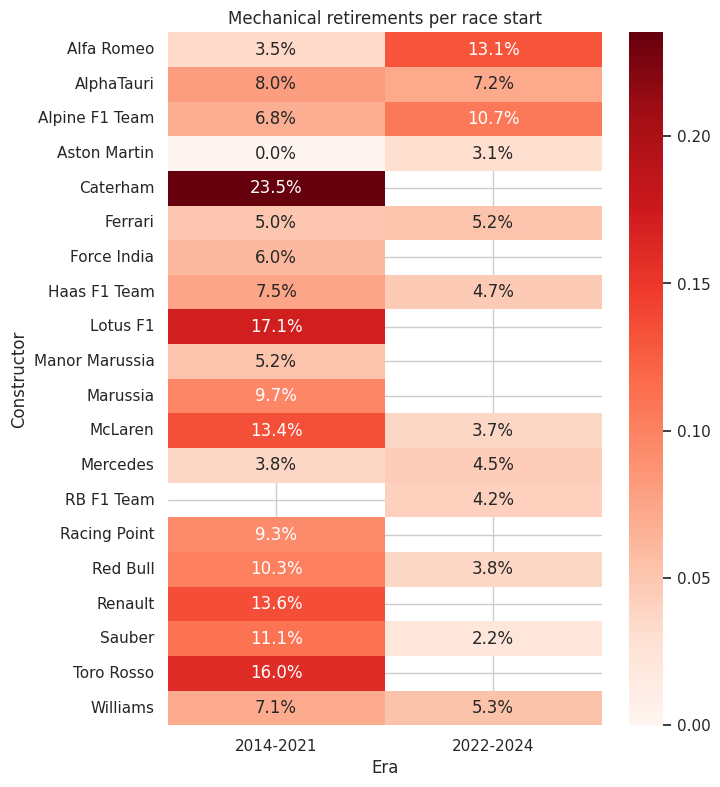

In [37]:
rate_table = retirement_rates.pivot(index='name', columns='era', values='rate')

plt.figure(figsize=(7, 9))
sns.heatmap(rate_table, annot=True, fmt='.1%', cmap='Reds')
plt.title('Mechanical retirements per race start')
plt.xlabel('Era')
plt.ylabel('Constructor')
plt.show()

**Answer Q3.** In **2014–2021** the highest mechanical-retirement rates belong to **Caterham** (about 24%, but from only 34 starts), **Lotus F1** (about 17%), **Toro Rosso** (about 16% from 238 starts), **Renault** (about 14%) and **McLaren** (about 13% from 320 starts, the McLaren-Honda years). In **2022–2024** the leaders are **Alfa Romeo** (about 13%, 11 failures in 84 starts) and **Alpine** (about 11%), well ahead of AlphaTauri in third (about 7%). Overall, rates are clearly lower in the ground-effect era and most teams are near or below 5%, which suggests the hybrid power units had matured.

*Caveats:* small denominators (for example Caterham) make some rates unstable, and rebranded teams (Toro Rosso → AlphaTauri → RB) appear as separate constructor IDs. The keyword classification is a judgement call, so the full list of non-mechanical statuses is printed above so it can be checked. *Grain:* one row per driver-race; the denominator is race starts only.

## 7. Feature engineering: the leakage-safe modelling table

**Modelling population:** drivers who took the start from a grid slot (`grid > 0`, and not `F`/`W`/`E`). Drivers who failed to qualify or withdrew never took part in the race, so a podium prediction for them is meaningless.

**Leakage rule:** every form feature is computed from races *strictly before* the current one. Races are ordered by date, round and race ID. Cumulative counts subtract the current race, and rolling windows are shifted by one race. `results` is used only for the target and for these lagged statistics.

In [38]:
starters = results[~results['positionText'].isin(['F', 'W', 'E']) & (results['grid'] > 0)].copy()

starters = starters.merge(clean['races'][['raceId', 'year', 'round', 'circuitId', 'date']],
                          on='raceId', validate='many_to_one')
starters = starters.sort_values(['date', 'round', 'raceId', 'driverId']).reset_index(drop=True)

starters['podium'] = (starters['positionOrder'] <= 3).astype(int)
starters['win'] = (starters['positionOrder'] == 1).astype(int)
starters['starter_count'] = starters.groupby('raceId')['driverId'].transform('size')

print('Starters:', len(starters), '| podium share:', round(starters['podium'].mean(), 4))

Starters: 24878 | podium share: 0.1365


### 7.1 Driver form (past races only)

In [39]:
by_driver = starters.groupby('driverId')

starters['career_races'] = by_driver.cumcount()
starters['career_wins'] = by_driver['win'].cumsum() - starters['win']
starters['career_podiums'] = by_driver['podium'].cumsum() - starters['podium']
starters['avg_finish_last_5'] = by_driver['positionOrder'].transform(
    lambda s: s.shift().rolling(5, min_periods=1).mean())
starters['podium_rate_last_10'] = by_driver['podium'].transform(
    lambda s: s.shift().rolling(10, min_periods=1).mean())
starters['wins_this_season_so_far'] = (starters.groupby(['driverId', 'year'])['win'].cumsum()
                                       - starters['win'])

### 7.2 Constructor form (past races only)

We first collapse to one row per team per race (did *any* of the team's cars win or podium), then apply the same lag logic.

In [40]:
team_race = (starters.groupby(['raceId', 'constructorId'], as_index=False)
             .agg(date=('date', 'first'), round=('round', 'first'), year=('year', 'first'),
                  team_win=('win', 'max'), team_podium=('podium', 'max'))
             .sort_values(['date', 'round', 'raceId', 'constructorId']))

by_team = team_race.groupby('constructorId')
previous_races = by_team.cumcount().replace(0, np.nan)

team_race['constructor_wins_total'] = by_team['team_win'].cumsum() - team_race['team_win']
team_race['constructor_podium_rate'] = ((by_team['team_podium'].cumsum() - team_race['team_podium'])
                                        / previous_races)
team_race['constructor_wins_this_season'] = (team_race.groupby(['constructorId', 'year'])['team_win'].cumsum()
                                             - team_race['team_win'])

constructor_features = ['constructor_wins_total', 'constructor_podium_rate', 'constructor_wins_this_season']
starters = starters.merge(team_race[['raceId', 'constructorId'] + constructor_features],
                          on=['raceId', 'constructorId'], validate='many_to_one')

### 7.3 Driver profile, circuit context and qualifying

In [41]:
starters = starters.merge(clean['drivers'][['driverId', 'dob', 'nationality']],
                          on='driverId', validate='many_to_one')
starters = starters.merge(clean['circuits'][['circuitId', 'country', 'lat', 'alt']],
                          on='circuitId', validate='many_to_one')

starters['driver_age_at_race'] = (starters['date'] - starters['dob']).dt.days / 365.25
starters['is_home_race'] = (starters['nationality'].str.strip().map(COUNTRY) == starters['country']).astype(int)

In [42]:
quali = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_seconds', 'q2_seconds', 'q3_seconds']]
quali = quali.rename(columns={'position': 'quali_position'})

quali['best_quali_seconds'] = quali[['q1_seconds', 'q2_seconds', 'q3_seconds']].min(axis=1)
quali['quali_time_gap_to_pole'] = (quali['best_quali_seconds']
                                   - quali.groupby('raceId')['best_quali_seconds'].transform('min'))

starters = starters.merge(quali[['raceId', 'driverId', 'quali_position', 'quali_time_gap_to_pole']],
                          on=['raceId', 'driverId'], how='left', validate='one_to_one')
starters['grid_position'] = starters['grid']

### 7.4 The modelling table

| Group | Feature | Why it is valid at the pre-race cutoff |
|---|---|---|
| Grid / qualifying | `grid_position` | Final starting slot, fixed before lights out |
| | `quali_position`, `quali_time_gap_to_pole` | Qualifying is finished before the race (missing before the mid-1990s). The gap compares each driver's best Q1/Q2/Q3 lap with the pole sitter's best lap, so it mixes sessions |
| Driver form | `career_races`, `career_wins`, `career_podiums` | Counts over earlier races only |
| | `avg_finish_last_5`, `podium_rate_last_10` | Rolling windows shifted by one race |
| | `wins_this_season_so_far` | Wins in earlier rounds of the same season |
| Constructor form | `constructor_wins_total`, `constructor_podium_rate`, `constructor_wins_this_season` | Team results from earlier races only |
| Driver profile | `driver_age_at_race`, `is_home_race` | Date of birth, nationality and venue are known in advance |
| Race context | `year`, `round`, `starter_count` | Calendar facts; the number of starters is known once the grid is set |
| Circuit | `lat`, `alt`, `country` | Static circuit attributes |

`circuits.csv` has no track length or circuit type, so we do not invent them; latitude, altitude and country are the circuit fields that exist.

In [43]:
features = ['grid_position', 'quali_position', 'quali_time_gap_to_pole',
            'career_races', 'career_wins', 'career_podiums', 'avg_finish_last_5',
            'podium_rate_last_10', 'wins_this_season_so_far',
            'constructor_wins_total', 'constructor_podium_rate', 'constructor_wins_this_season',
            'driver_age_at_race', 'is_home_race',
            'year', 'round', 'starter_count',
            'lat', 'alt', 'country']
numeric_features = [f for f in features if f != 'country']

model_df = starters[['raceId', 'driverId', 'date', 'podium'] + features].copy()
model_df[numeric_features] = model_df[numeric_features].astype(float)
model_df = model_df.sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)

assert not model_df.duplicated(['raceId', 'driverId']).any()
print('Modelling table:', model_df.shape, '| podium share:', round(model_df['podium'].mean(), 4))
model_df.head(10)

Modelling table: (24878, 24) | podium share: 0.1365


,raceId,driverId,date,podium,grid_position,quali_position,quali_time_gap_to_pole,career_races,career_wins,career_podiums,...,constructor_podium_rate,constructor_wins_this_season,driver_age_at_race,is_home_race,year,round,starter_count,lat,alt,country
0,833,579,1950-05-13,0,3.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,38.885695,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
1,833,589,1950-05-13,0,11.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,50.773443,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
2,833,619,1950-05-13,0,13.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,36.312115,1.0,1950.0,1.0,23.0,52.0786,153.0,UK
3,833,627,1950-05-13,0,9.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,44.517454,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
4,833,640,1950-05-13,0,8.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,35.986311,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
5,833,642,1950-05-13,1,1.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,43.534565,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
6,833,660,1950-05-13,0,21.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,33.752225,0.0,1950.0,1.0,23.0,52.0786,153.0,UK
7,833,661,1950-05-13,0,10.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,37.596167,1.0,1950.0,1.0,23.0,52.0786,153.0,UK
8,833,666,1950-05-13,0,10.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,31.572895,1.0,1950.0,1.0,23.0,52.0786,153.0,UK
9,833,669,1950-05-13,0,5.0,NaN,NaN,0.0,0.0,0.0,...,NaN,0.0,35.827515,0.0,1950.0,1.0,23.0,52.0786,153.0,UK


In [44]:
model_df[features].isna().mean().sort_values(ascending=False).to_frame('missing share')

,missing share
quali_time_gap_to_pole,0.589838
quali_position,0.584171
avg_finish_last_5,0.031514
podium_rate_last_10,0.031514
constructor_podium_rate,0.012501
grid_position,0.000000
career_races,0.000000
career_podiums,0.000000
career_wins,0.000000
wins_this_season_so_far,0.000000


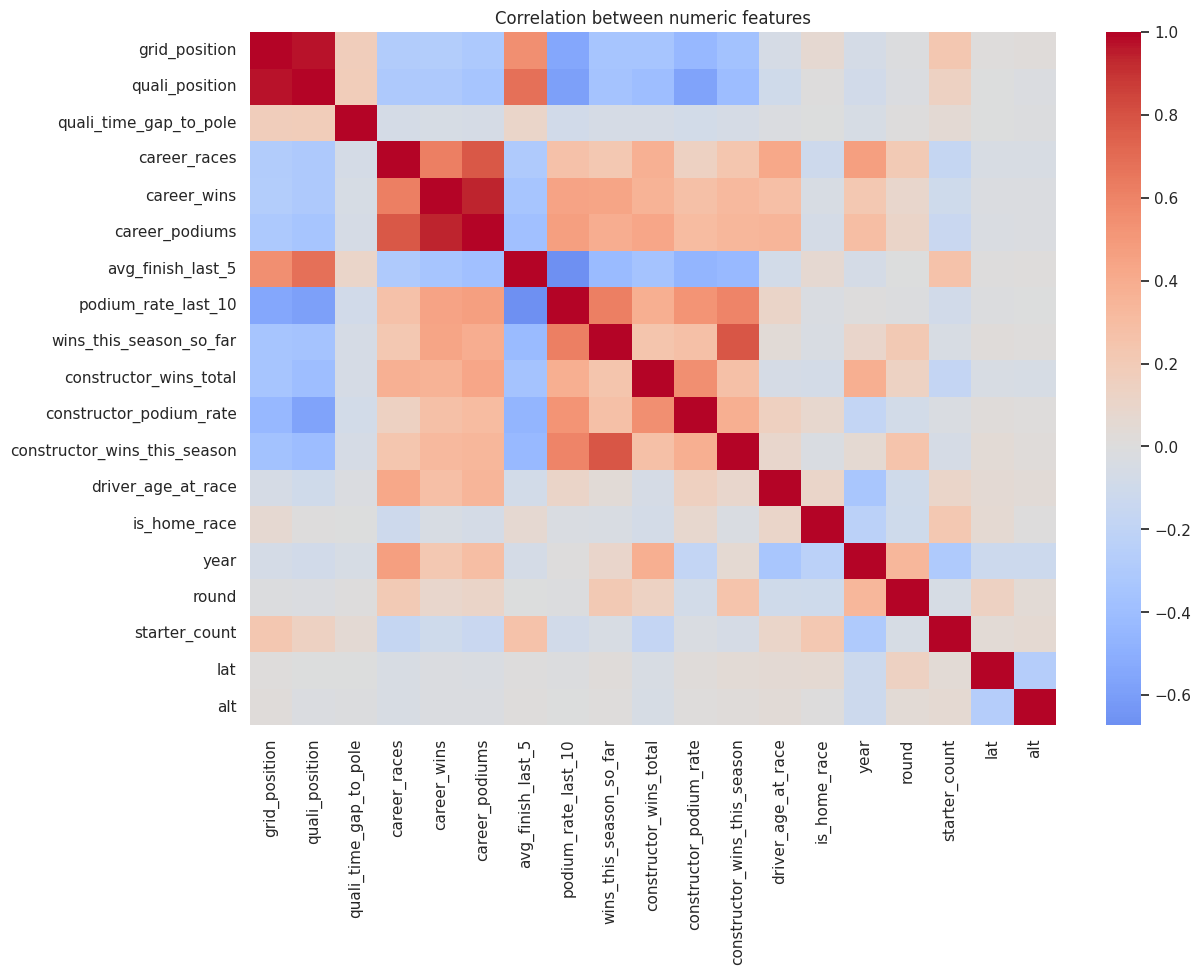

In [45]:
plt.figure(figsize=(13, 9))
sns.heatmap(model_df[numeric_features].corr(), cmap='coolwarm', center=0)
plt.title('Correlation between numeric features')
plt.show()

### 7.5 Evidence for the feature choices

Before training anything, we check that each feature group actually moves the podium rate. We use the **training seasons only (≤ 2019)**, so the validation and test seasons cannot influence which features we keep.

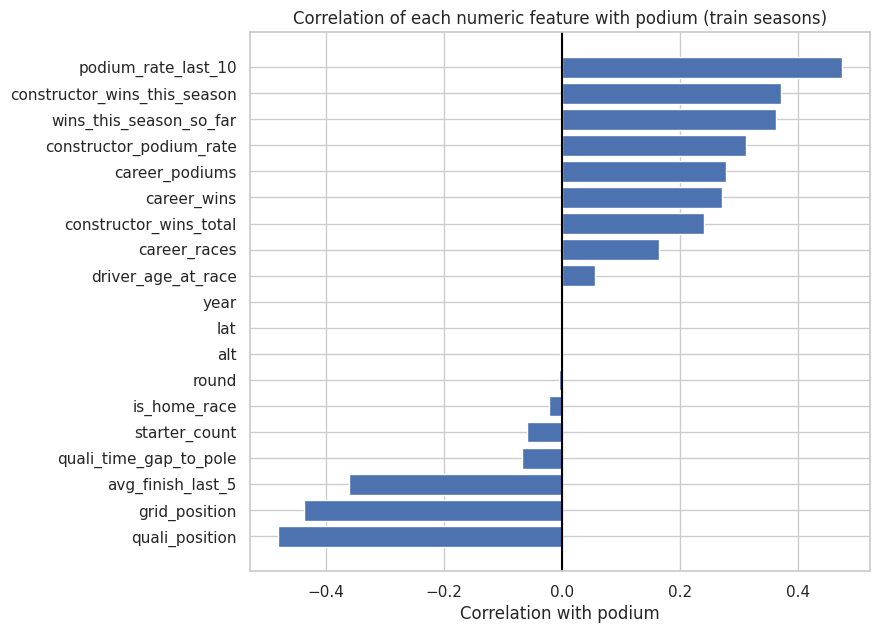

In [46]:
eda = model_df[model_df['year'] <= 2019]

target_corr = eda[numeric_features].corrwith(eda['podium']).sort_values()

plt.figure(figsize=(8, 7))
plt.barh(target_corr.index, target_corr.values)
plt.axvline(0, color='black')
plt.title('Correlation of each numeric feature with podium (train seasons)')
plt.xlabel('Correlation with podium')
plt.show()

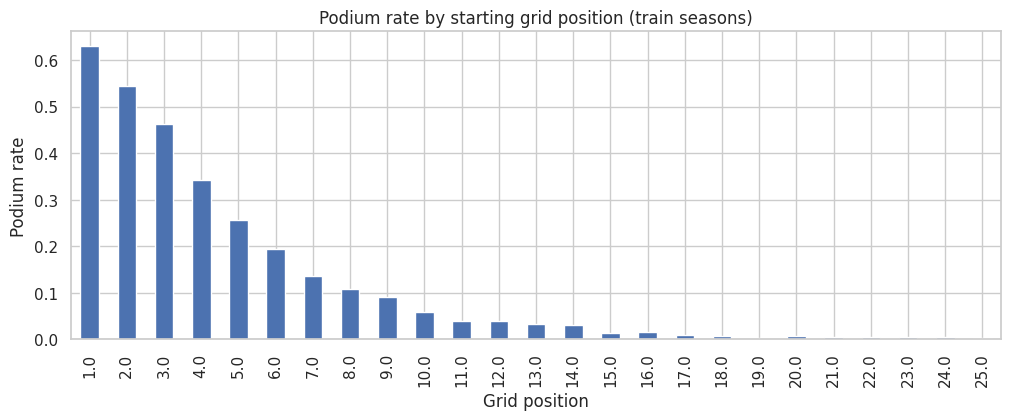

In [47]:
grid_rate = eda[eda['grid_position'] <= 25].groupby('grid_position')['podium'].mean()

grid_rate.plot(kind='bar', figsize=(12, 4))
plt.title('Podium rate by starting grid position (train seasons)')
plt.xlabel('Grid position')
plt.ylabel('Podium rate')
plt.show()

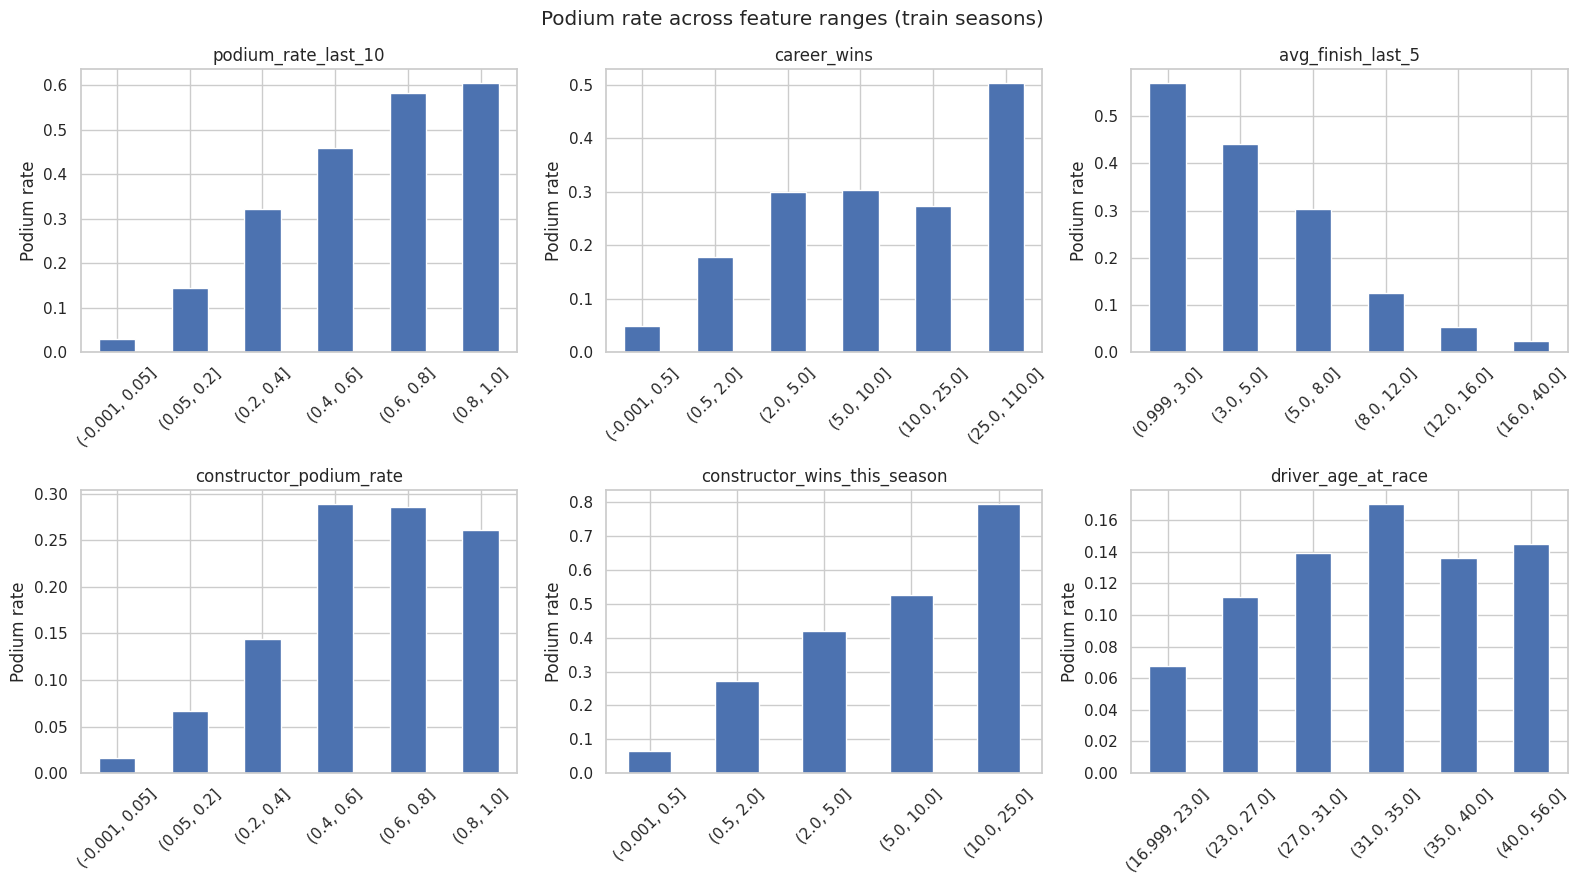

In [48]:
def podium_rate_by_bins(ax, feature, bins):
    binned = pd.cut(eda[feature], bins=bins, include_lowest=True)
    rate = eda.groupby(binned, observed=True)['podium'].mean()
    rate.plot(kind='bar', ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.set_ylabel('Podium rate')
    ax.tick_params(axis='x', rotation=45)


fig, axes = plt.subplots(2, 3, figsize=(16, 9))
podium_rate_by_bins(axes[0, 0], 'podium_rate_last_10', [0, 0.05, 0.2, 0.4, 0.6, 0.8, 1])
podium_rate_by_bins(axes[0, 1], 'career_wins', [0, 0.5, 2, 5, 10, 25, 110])
podium_rate_by_bins(axes[0, 2], 'avg_finish_last_5', [1, 3, 5, 8, 12, 16, 40])
podium_rate_by_bins(axes[1, 0], 'constructor_podium_rate', [0, 0.05, 0.2, 0.4, 0.6, 0.8, 1])
podium_rate_by_bins(axes[1, 1], 'constructor_wins_this_season', [0, 0.5, 2, 5, 10, 25])
podium_rate_by_bins(axes[1, 2], 'driver_age_at_race', [17, 23, 27, 31, 35, 40, 56])
plt.suptitle('Podium rate across feature ranges (train seasons)')
plt.tight_layout()
plt.show()

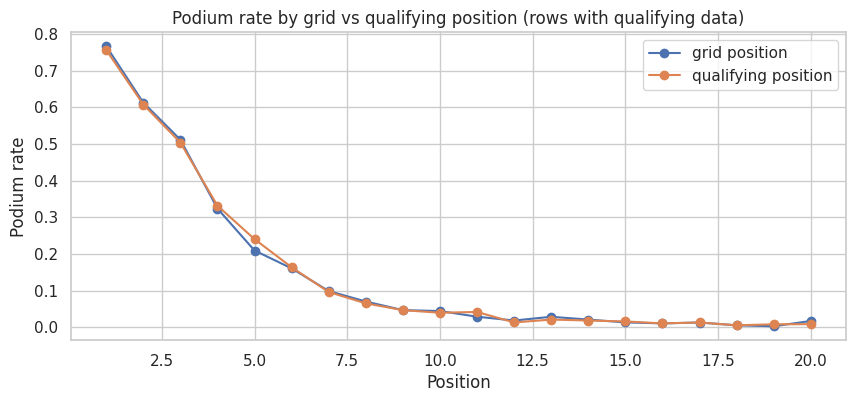

Home vs away podium rate (train seasons):
is_home_race
0.0    0.137
1.0    0.112
Name: podium, dtype: float64


In [49]:
with_quali = eda.dropna(subset=['quali_position'])
compare = pd.DataFrame({
    'grid position': with_quali.groupby('grid_position')['podium'].mean(),
    'qualifying position': with_quali.groupby('quali_position')['podium'].mean()
}).loc[1:20]

compare.plot(figsize=(10, 4), marker='o')
plt.title('Podium rate by grid vs qualifying position (rows with qualifying data)')
plt.xlabel('Position')
plt.ylabel('Podium rate')
plt.show()

print('Home vs away podium rate (train seasons):')
print(eda.groupby('is_home_race')['podium'].mean().round(3))

**What the evidence shows, group by group**
- **Grid / qualifying:** the strongest single signals. Correlation with podium is −0.48 for qualifying position and −0.44 for grid; the podium rate falls steeply with starting position and is very low beyond the top ten. The grid and qualifying curves are close but not identical, because penalties move drivers after qualifying. Both are kept: grid covers every season, qualifying adds detail when it exists. `quali_time_gap_to_pole` is much weaker (−0.07), probably because it mixes Q1/Q2/Q3 laps (see 7.4).
- **Driver form:** recent podium rate is the most correlated feature overall (+0.47), with a better recent average finish (−0.36) and season wins (+0.36) close behind. The podium rate rises steadily across their ranges, so past results carry information the grid alone does not.
- **Constructor form:** wins this season (+0.37) and recent podium rate (+0.31) put drivers on the podium far more often, which captures car performance. These are correlated with driver form, so the ablation checks whether they add anything on top of it.
- **Driver profile:** age is only weakly related (+0.05). The home flag is slightly *negative* in the raw data (13.7% away vs 11.2% home), and Q2 showed no advantage once the grid is controlled for. We keep both as weak context features and let the ablation test them.
- **Race context and circuit** (`year`, `round`, `starter_count`, `lat`, `alt`, `country`): correlations near zero. We keep them because they encode era and field size, which change how hard a podium is (Section 2), and the ablation tests whether they help.

## 8. Dataset splitting

We split **by season**, not randomly:
- **Train:** 1950–2019
- **Validation:** 2020–2021 (used for model selection, the F1 threshold and the preprocessing choice)
- **Test:** 2022–2024 (used once, at the end)

A random split would put races from the same season, and even the same weekend, in both train and test. The model would then be scored on a past it has partly seen. The temporal split matches how the model would actually be used: trained on history and applied to future races. The 2022 cut also lines up with a major regulation change, so the test set is a genuine out-of-era check.

In [50]:
train = model_df[model_df['year'] <= 2019]
val = model_df[model_df['year'].between(2020, 2021)]
test = model_df[model_df['year'] >= 2022]

assert train['year'].max() < val['year'].min() < test['year'].min()

X_train, y_train = train[features], train['podium']
X_val, y_val = val[features], val['podium']
X_test, y_test = test[features], test['podium']

pd.DataFrame({
    'rows': [len(train), len(val), len(test)],
    'first season': [train['year'].min(), val['year'].min(), test['year'].min()],
    'last season': [train['year'].max(), val['year'].max(), test['year'].max()],
    'podium share': [y_train.mean(), y_val.mean(), y_test.mean()]
}, index=['train', 'validation', 'test']).round(3)

,rows,first season,last season,podium share
train,22804,1950.0,2019.0,0.135
validation,759,2020.0,2021.0,0.154
test,1315,2022.0,2024.0,0.155


## 9. Preprocessing-order experiment

We need three preprocessing steps: **imputation** (qualifying features are missing for about 58% of rows), **one-hot encoding** (`country`) and **scaling**. We compare three orders using the same logistic-regression model:
- **Pipeline A:** impute (median) → encode → scale, with numeric and categorical columns handled separately
- **Pipeline B:** encode → impute (median) → scale, with one imputer for the whole encoded matrix, so the one-hot columns are also scaled
- **Pipeline C:** scale → impute. The scaler is fitted on the observed values only, and the gaps are then filled with 0, which in scaled units is the **mean** rather than the median

All three add missing-value indicator columns, so the model can still tell a real qualifying value from a filled one. Everything is fitted on the training set only.

In [51]:
def make_preprocessor_a(columns):
    numeric = [c for c in columns if c != 'country']
    categorical = [c for c in columns if c == 'country']
    numeric_steps = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler())
    ])
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([('numeric', numeric_steps, numeric),
                              ('category', categorical_steps, categorical)])


def make_preprocessor_b(columns):
    numeric = [c for c in columns if c != 'country']
    categorical = [c for c in columns if c == 'country']
    encode = ColumnTransformer([
        ('numeric', 'passthrough', numeric),
        ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ])
    return Pipeline([
        ('encode', encode),
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler())
    ])


def make_preprocessor_c(columns):
    numeric = [c for c in columns if c != 'country']
    categorical = [c for c in columns if c == 'country']
    # StandardScaler ignores NaN when fitting, so we can scale first and fill afterwards
    numeric_steps = Pipeline([
        ('scale', StandardScaler()),
        ('impute', SimpleImputer(strategy='constant', fill_value=0, add_indicator=True))
    ])
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([('numeric', numeric_steps, numeric),
                              ('category', categorical_steps, categorical)])

In [52]:
experiment_rows = {}
for label, make_preprocessor in [('A: impute -> encode -> scale', make_preprocessor_a),
                                 ('B: encode -> impute -> scale', make_preprocessor_b),
                                 ('C: scale -> impute (mean)', make_preprocessor_c)]:
    pipe = Pipeline([
        ('prep', make_preprocessor(features)),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
    ])
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_val)[:, 1]
    experiment_rows[label] = {'validation PR-AUC': average_precision_score(y_val, prob),
                              'validation ROC-AUC': roc_auc_score(y_val, prob)}

prep_table = pd.DataFrame(experiment_rows).T
prep_table.round(4)

,validation PR-AUC,validation ROC-AUC
A: impute -> encode -> scale,0.7213,0.9285
B: encode -> impute -> scale,0.7176,0.9287
C: scale -> impute (mean),0.7177,0.9283


In [53]:
chosen_label = prep_table['validation PR-AUC'].idxmax()
preprocessors = {'A': make_preprocessor_a, 'B': make_preprocessor_b, 'C': make_preprocessor_c}
chosen_preprocessor = preprocessors[chosen_label[0]]
print('Chosen preprocessing order:', chosen_label)

Chosen preprocessing order: A: impute -> encode -> scale


**Result.** Pipeline A scores best (validation PR-AUC 0.721, vs 0.718 for both B and C), but the spread is only 0.004. That is far smaller than the uncertainty of PR-AUC on 759 validation rows (the bootstrap in 10.3 gives intervals about 0.17 wide). The order of the steps therefore makes no practical difference here, which makes sense: all three handle the missing qualifying values the same way, with a fill value plus an indicator column. We keep **Pipeline A**. It has the best score, and it is also the most standard design, because each column type gets its own steps and the one-hot columns are not rescaled.

### 9.1 Effect of preprocessing on the data

Below we follow four numeric features through median imputation and scaling, fitted on the training set. `quali_position` is the interesting case: 58% of its training values are missing.

In [54]:
demo_cols = ['grid_position', 'quali_position', 'career_wins', 'driver_age_at_race']

demo_imputer = SimpleImputer(strategy='median').fit(X_train[demo_cols])
imputed = pd.DataFrame(demo_imputer.transform(X_train[demo_cols]), columns=demo_cols)
scaled = pd.DataFrame(StandardScaler().fit_transform(imputed), columns=demo_cols)

summary = pd.concat({
    'raw': X_train[demo_cols].describe().T[['count', 'mean', 'std', 'min', 'max']],
    'after imputation': imputed.describe().T[['count', 'mean', 'std', 'min', 'max']],
    'after scaling': scaled.describe().T[['mean', 'std', 'min', 'max']]
}, axis=1)
summary.round(2)

raw                            after imputation  \
                      count   mean    std    min   max            count   
grid_position       22804.0  11.99   6.89   1.00  34.0          22804.0   
quali_position       8272.0  11.33   6.36   1.00  26.0          22804.0   
career_wins         22804.0   3.93  10.20   0.00  91.0          22804.0   
driver_age_at_race  22804.0  30.11   5.21  17.45  55.8          22804.0   

                                              after scaling                   
                     mean    std    min   max          mean  std   min   max  
grid_position       11.99   6.89   1.00  34.0          -0.0  1.0 -1.59  3.19  
quali_position      11.12   3.83   1.00  26.0           0.0  1.0 -2.64  3.88  
career_wins          3.93  10.20   0.00  91.0          -0.0  1.0 -0.39  8.54  
driver_age_at_race  30.11   5.21  17.45  55.8          -0.0  1.0 -2.43  4.93

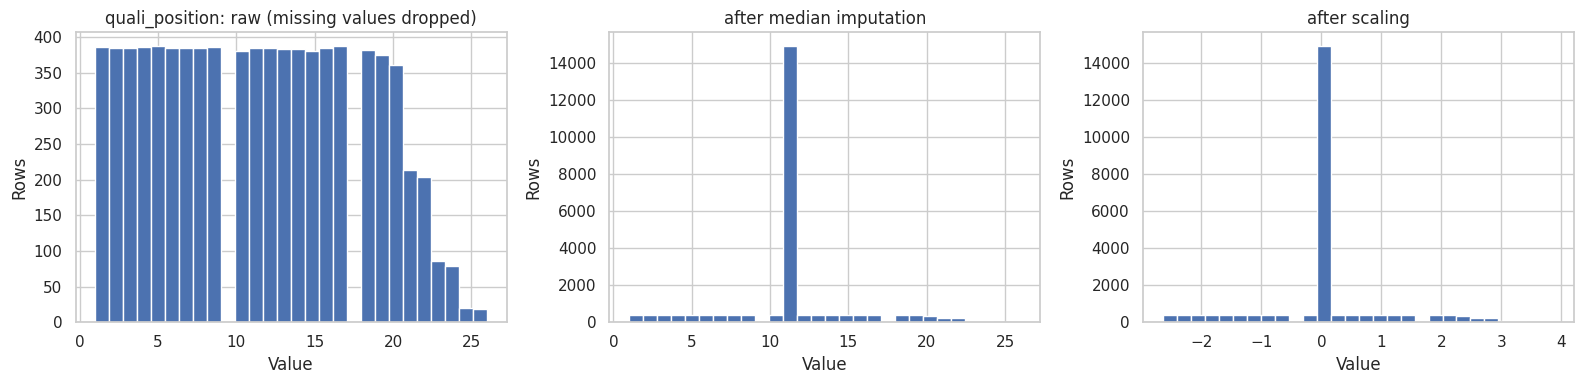

Median used to fill quali_position: 11.0


In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(X_train['quali_position'].dropna(), bins=28)
axes[0].set_title('quali_position: raw (missing values dropped)')
axes[1].hist(imputed['quali_position'], bins=28)
axes[1].set_title('after median imputation')
axes[2].hist(scaled['quali_position'], bins=28)
axes[2].set_title('after scaling')

for ax in axes:
    ax.set_xlabel('Value')
    ax.set_ylabel('Rows')

plt.tight_layout()
plt.show()

print('Median used to fill quali_position:', demo_imputer.statistics_[1])

**What preprocessing does:**
- **Imputation** only touches the missing rows. `quali_position` goes from 8,272 observed values to 22,804, with all 14,532 gaps filled with the median (11). The mean barely moves (11.3 → 11.1), but the standard deviation shrinks from 6.4 to 3.8, and the middle plot shows one huge spike at 11. On its own this would blur the feature, which is why every pipeline adds a missing-indicator column that tells the model which rows were filled. The features without missing values are unchanged.
- **Scaling** changes the units only: every column ends up with mean 0 and standard deviation 1, and the shape of each distribution stays the same. Before scaling, `career_wins` ranges from 0 to 91 while `grid_position` ranges from 1 to 34, so without scaling the large-unit features would dominate the weights in logistic regression and the neural network. After scaling, `career_wins` still has a long right tail (max 8.5 standard deviations), because a few drivers have far more wins than everyone else.

## 10. Model training and evaluation

All three models use the **same rows, the same features and the same preprocessing**, so their scores are directly comparable.

| Model | Role | How it works |
|---|---|---|
| Logistic regression | **Baseline** | One weighted sum of the features passed through a sigmoid; linear decision boundary |
| Random forest | Statistical model | Many decision trees trained on bootstrapped rows and random feature subsets; the trees vote, which captures non-linear interactions such as *grid × constructor form* |
| Shallow neural network | Neural network | One or two hidden ReLU layers and a sigmoid output, trained with binary cross-entropy and Adam |

**Metrics.** Podiums are only about 14% of the rows, so our **primary metric is PR-AUC**: it measures how well the model ranks real podium finishers above everyone else, and it is not inflated by the large number of easy negatives. **ROC-AUC** is the secondary metric for overall separation. **F1** is reported at a probability threshold chosen on the validation set; the test set is never used to choose anything.

Logistic regression and the random forest use `class_weight='balanced'` to compensate for the class imbalance; for the network, class weighting is one of the settings we compare in 10.1.

In [56]:
def build_network(n_features, hidden_units):
    model = keras.Sequential([layers.Input(shape=(n_features,))])
    for units in hidden_units:
        model.add(layers.Dense(units, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

The Keras network is wrapped in a small class with `fit` / `predict_proba`, so that it sits in an sklearn `Pipeline` exactly like the other two models. The same preprocessing is then applied automatically, and permutation importance and the ablation treat all models the same way.

**Early stopping** watches `val_loss` on `validation_split=0.15`. Keras takes this split from the *last* 15% of the training rows, and our training rows are in date order, so the network is stopped on the most recent training seasons (roughly 2012–2019). The real 2020–2021 validation set stays untouched for model selection.

In [57]:
class KerasPodiumClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden_units=(64, 32), class_weight=None, epochs=200, batch_size=32, patience=15):
        self.hidden_units = hidden_units
        self.class_weight = class_weight
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience

    def fit(self, X, y):
        keras.utils.set_random_seed(SEED)
        y = np.asarray(y)

        weights = None
        if self.class_weight == 'balanced':
            # same formula sklearn uses: n_samples / (n_classes * n_samples_in_class)
            weights = {0: len(y) / (2 * (y == 0).sum()), 1: len(y) / (2 * (y == 1).sum())}

        self.network_ = build_network(X.shape[1], self.hidden_units)
        early_stop = EarlyStopping(monitor='val_loss', patience=self.patience, restore_best_weights=True)
        self.history_ = self.network_.fit(
            np.asarray(X, dtype='float32'), y,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            class_weight=weights,
            callbacks=[early_stop],
            verbose=0
        )
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        podium = self.network_.predict(np.asarray(X, dtype='float32'), verbose=0).ravel()
        return np.column_stack([1 - podium, podium])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [58]:
def make_model(model_name, params):
    if model_name == 'Logistic regression':
        return LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED, **params)
    if model_name == 'Random forest':
        return RandomForestClassifier(n_estimators=160, class_weight='balanced_subsample',
                                      n_jobs=-1, random_state=SEED, **params)
    return KerasPodiumClassifier(**params)


def build_pipeline(model_name, columns, params):
    return Pipeline([('prep', chosen_preprocessor(columns)), ('model', make_model(model_name, params))])

### 10.1 Hyperparameter and architecture comparison

Each model family gets a few candidate settings. Every candidate is trained on the training seasons and scored on the **validation** PR-AUC; the best candidate of each family goes forward to the final comparison. The test set plays no part in this.

- **Logistic regression:** regularisation strength `C` (smaller means stronger regularisation).
- **Random forest:** tree depth and leaf size, which control how closely the trees can fit the training seasons.
- **Neural network:** one hidden layer vs two, with and without class weighting. In the previous run, the unweighted network early-stopped after only a few epochs and needed a very low F1 threshold, a sign that it was mostly learning to predict "no podium".

In [59]:
search_space = {
    'Logistic regression': [{'C': 0.1}, {'C': 1.0}, {'C': 10.0}],
    'Random forest': [{'max_depth': 6, 'min_samples_leaf': 4},
                      {'max_depth': 12, 'min_samples_leaf': 4},
                      {'max_depth': None, 'min_samples_leaf': 10}],
    'Neural network': [{'hidden_units': (32,), 'class_weight': None},
                       {'hidden_units': (64, 32), 'class_weight': None},
                       {'hidden_units': (32,), 'class_weight': 'balanced'},
                       {'hidden_units': (64, 32), 'class_weight': 'balanced'}]
}

tuning_rows = []
fitted = {}
best_params = {}
for name, candidates in search_space.items():
    best_score = -1
    for params in candidates:
        pipe = build_pipeline(name, features, params).fit(X_train, y_train)
        score = average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])
        tuning_rows.append({'model': name, 'settings': str(params), 'validation PR-AUC': score})
        if score > best_score:
            best_score = score
            best_params[name] = params
            fitted[name] = pipe
    print(f'{name}: best settings {best_params[name]} (validation PR-AUC {best_score:.3f})')

tuning = pd.DataFrame(tuning_rows)
tuning.round(4)

Logistic regression: best settings {'C': 0.1} (validation PR-AUC 0.725)
Random forest: best settings {'max_depth': None, 'min_samples_leaf': 10} (validation PR-AUC 0.750)
Neural network: best settings {'hidden_units': (64, 32), 'class_weight': None} (validation PR-AUC 0.733)


,model,settings,validation PR-AUC
0,Logistic regression,{'C': 0.1},0.7249
1,Logistic regression,{'C': 1.0},0.7213
2,Logistic regression,{'C': 10.0},0.7204
3,Random forest,"{'max_depth': 6, 'min_samples_leaf': 4}",0.6970
4,Random forest,"{'max_depth': 12, 'min_samples_leaf': 4}",0.7259
5,Random forest,"{'max_depth': None, 'min_samples_leaf': 10}",0.7502
6,Neural network,"{'hidden_units': (32,), 'class_weight': None}",0.7231
7,Neural network,"{'hidden_units': (64, 32), 'class_weight': None}",0.7335
8,Neural network,"{'hidden_units': (32,), 'class_weight': 'balan...",0.7044
9,Neural network,"{'hidden_units': (64, 32), 'class_weight': 'ba...",0.6631


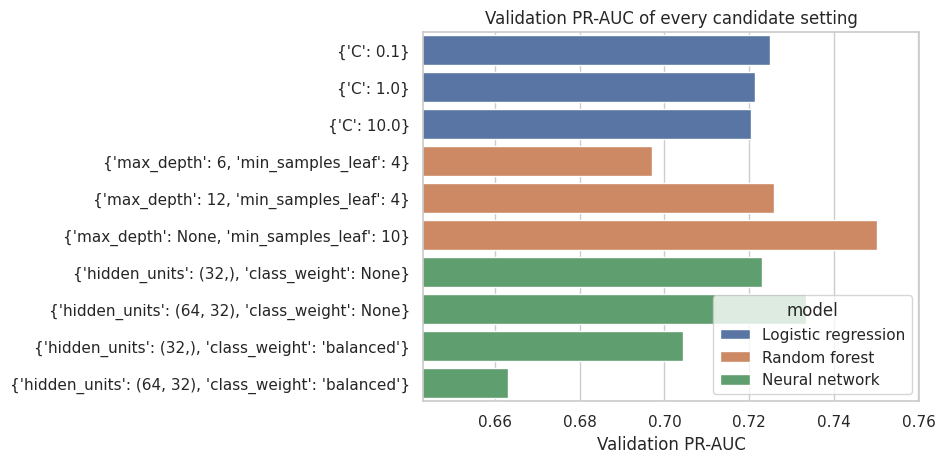

In [60]:
sns.barplot(data=tuning, x='validation PR-AUC', y='settings', hue='model', dodge=False)
plt.title('Validation PR-AUC of every candidate setting')
plt.xlabel('Validation PR-AUC')
plt.ylabel('')
plt.xlim(tuning['validation PR-AUC'].min() - 0.02, tuning['validation PR-AUC'].max() + 0.01)
plt.show()

**What the comparison shows**
- **Logistic regression** is barely affected by `C` (0.720–0.725). The strongest regularisation (`C = 0.1`) is marginally best, which suggests the correlated form features benefit from a little shrinkage.
- **Random forest** depends strongly on how much freedom the trees get. Shallow trees (`max_depth = 6`) underfit (0.697), while fully grown trees with at least 10 rows per leaf score best (0.750). The leaf-size limit, rather than a depth limit, is enough to stop the trees memorising single races.
- **Neural network:** two hidden layers (64, 32) beat one (0.734 vs 0.723). Class weighting *hurt* (0.704 and 0.663), so our guess from the previous run was wrong: up-weighting the rare class changed what the network optimised and gave a worse ranking of podium finishers here. The low F1 threshold of the unweighted network is a calibration issue, which the validation-tuned threshold already handles. The best network still early-stops after about 17 epochs, so it learns what it can very quickly.

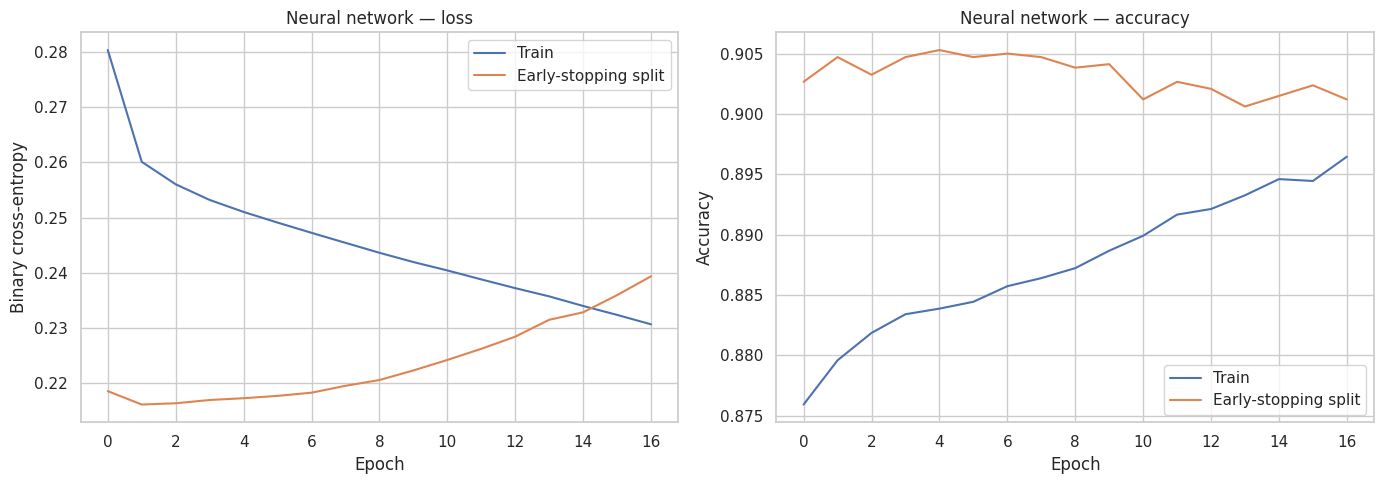

Epochs trained: 17


In [61]:
history = fitted['Neural network'].named_steps['model'].history_.history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['loss'], label='Train')
axes[0].plot(history['val_loss'], label='Early-stopping split')
axes[0].set_title('Neural network — loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary cross-entropy')
axes[0].legend()

axes[1].plot(history['accuracy'], label='Train')
axes[1].plot(history['val_accuracy'], label='Early-stopping split')
axes[1].set_title('Neural network — accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

print('Epochs trained:', len(history['loss']))

### 10.2 Threshold selection and comparison table

For each model we pick the probability threshold that maximises F1 **on the validation set**, then report every metric on train, validation and test using that threshold.

In [62]:
def score_model(model, X, y, threshold):
    probability = model.predict_proba(X)[:, 1]
    prediction = (probability >= threshold).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y, probability),
        'PR-AUC': average_precision_score(y, probability),
        'F1': f1_score(y, prediction),
        'accuracy': accuracy_score(y, prediction),
        'precision': precision_score(y, prediction, zero_division=0),
        'recall': recall_score(y, prediction)
    }


thresholds = {}
rows = []
for name, model in fitted.items():
    prob = model.predict_proba(X_val)[:, 1]
    candidates = np.linspace(0.05, 0.95, 91)
    thresholds[name] = max(candidates, key=lambda t: f1_score(y_val, prob >= t, zero_division=0))

    for split, X, y in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
        rows.append({'model': name, 'split': split, **score_model(model, X, y, thresholds[name]),
                     'threshold': thresholds[name]})

scores = pd.DataFrame(rows)
scores.round(3)

,model,split,ROC-AUC,PR-AUC,F1,accuracy,precision,recall,threshold
0,Logistic regression,train,0.900,0.561,0.579,0.853,0.471,0.750,0.65
1,Logistic regression,validation,0.928,0.725,0.719,0.905,0.662,0.786,0.65
2,Logistic regression,test,0.930,0.700,0.660,0.863,0.537,0.858,0.65
3,Random forest,train,0.953,0.755,0.677,0.911,0.661,0.694,0.70
4,Random forest,validation,0.930,0.750,0.722,0.916,0.735,0.709,0.70
5,Random forest,test,0.933,0.695,0.665,0.891,0.637,0.696,0.70
6,Neural network,train,0.903,0.578,0.584,0.855,0.476,0.756,0.23
7,Neural network,validation,0.925,0.733,0.714,0.905,0.667,0.769,0.23
8,Neural network,test,0.920,0.659,0.631,0.875,0.583,0.686,0.23


### 10.3 Choosing the final model

The validation set has only 759 rows (about 117 podiums), so small differences in PR-AUC between models can be pure noise. Before preferring a more complex model, we check whether its advantage is real:

1. Resample the validation rows with replacement 1,000 times (a **bootstrap**) and recompute every model's PR-AUC on each resample. The same resample is used for all models, so the comparison is paired.
2. Find the model with the highest validation PR-AUC.
3. Going from simplest to most complex (logistic regression → random forest → neural network), choose the **first model that is not significantly worse** than the top one, meaning the 95% interval of its PR-AUC difference to the top model includes zero.

This keeps the baseline unless a more complex model clearly earns its extra complexity, which is the purpose of having a baseline. It still uses only the validation set.

In [63]:
rng = np.random.default_rng(SEED)
val_probs = {name: model.predict_proba(X_val)[:, 1] for name, model in fitted.items()}
y_val_array = y_val.to_numpy()

bootstrap = {name: [] for name in fitted}
for _ in range(1000):
    sample = rng.integers(0, len(y_val_array), len(y_val_array))
    for name in fitted:
        bootstrap[name].append(average_precision_score(y_val_array[sample], val_probs[name][sample]))
bootstrap = pd.DataFrame(bootstrap)

point_scores = pd.Series({name: average_precision_score(y_val, val_probs[name]) for name in fitted})
top_name = point_scores.idxmax()
# for every bootstrap sample: PR-AUC of the top model minus PR-AUC of each model
differences = bootstrap.rsub(bootstrap[top_name], axis=0)

selection = pd.DataFrame({
    'validation PR-AUC': point_scores,
    'bootstrap 2.5%': bootstrap.quantile(0.025),
    'bootstrap 97.5%': bootstrap.quantile(0.975),
    'gap to top model (2.5%)': differences.quantile(0.025),
    'gap to top model (97.5%)': differences.quantile(0.975)
})
selection.round(3)

,validation PR-AUC,bootstrap 2.5%,bootstrap 97.5%,gap to top model (2.5%),gap to top model (97.5%)
Logistic regression,0.725,0.640,0.808,-0.006,0.059
Random forest,0.750,0.669,0.828,0.000,0.000
Neural network,0.733,0.650,0.814,-0.015,0.049


In [64]:
complexity_order = ['Logistic regression', 'Random forest', 'Neural network']
for name in complexity_order:
    # not significantly worse: the 95% interval of the gap includes zero
    if differences[name].quantile(0.025) <= 0:
        best_name = name
        break

best_model = fitted[best_name]
val_scores = scores[scores['split'] == 'validation'].set_index('model')

print('Highest validation PR-AUC:', top_name)
print('Selected model:', best_name)

Highest validation PR-AUC: Random forest
Selected model: Logistic regression


**Selection result.** The random forest has the highest validation PR-AUC (0.750), ahead of the network (0.733) and logistic regression (0.725). But the bootstrap intervals overlap almost completely (0.64–0.81 for logistic regression vs 0.67–0.83 for the forest). The 95% interval of the forest's advantage over logistic regression runs from −0.006 to +0.059, so it includes zero. On this validation set we cannot show that the forest is really better, so the rule keeps the **logistic-regression baseline**.

Logistic regression is also the easiest model to explain and the most stable across eras. Its test PR-AUC (0.700) is in fact the best of the three, essentially tied with the forest (0.695) and clearly above the network (0.659). The test set was **not** used for this choice; it only confirms afterwards that the choice holds up.

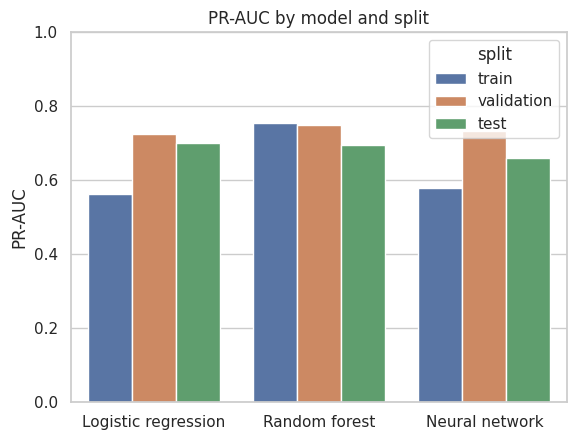

In [65]:
sns.barplot(data=scores, x='model', y='PR-AUC', hue='split')
plt.title('PR-AUC by model and split')
plt.xlabel('')
plt.ylabel('PR-AUC')
plt.ylim(0, 1)
plt.show()

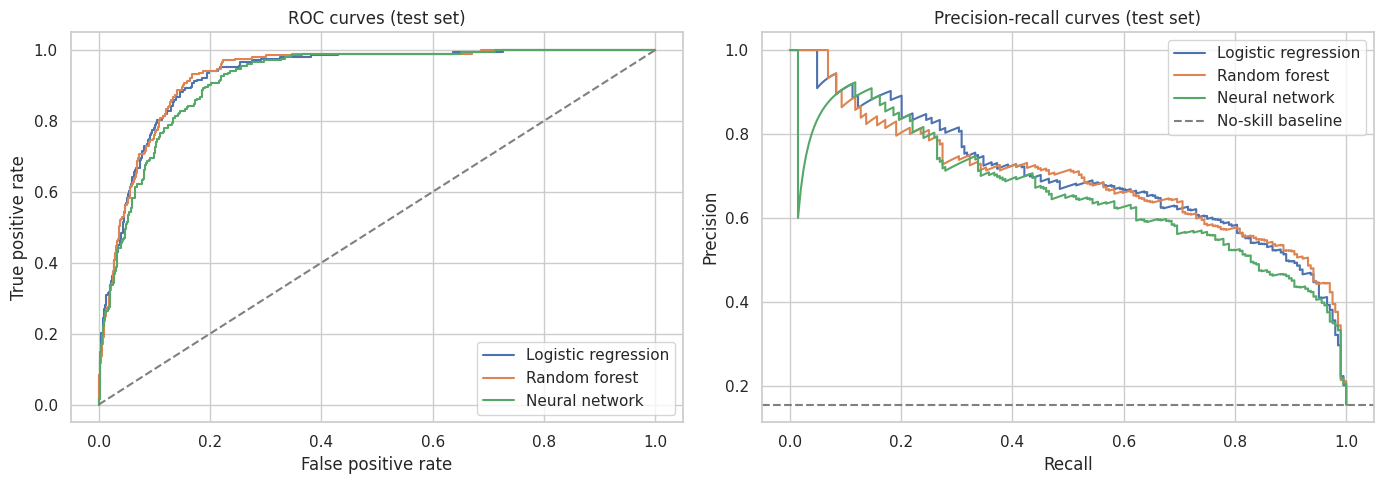

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, model in fitted.items():
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)

axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[0].set_title('ROC curves (test set)')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].legend()

axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='No-skill baseline')
axes[1].set_title('Precision-recall curves (test set)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

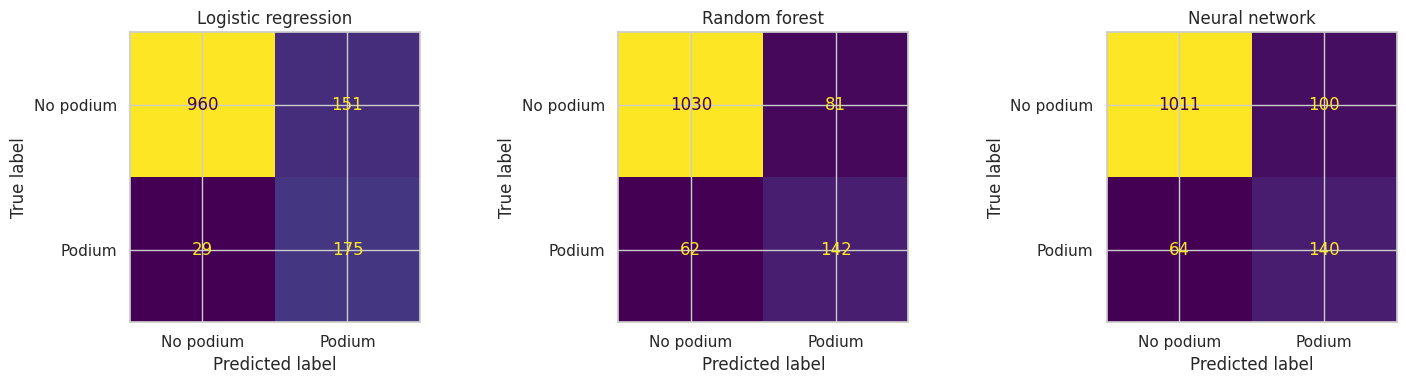

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, fitted.items()):
    prediction = model.predict_proba(X_test)[:, 1] >= thresholds[name]
    ConfusionMatrixDisplay(confusion_matrix(y_test, prediction),
                           display_labels=['No podium', 'Podium']).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [68]:
gaps = scores.pivot(index='model', columns='split', values='PR-AUC')
gaps['train - validation'] = gaps['train'] - gaps['validation']
gaps[['train', 'validation', 'test', 'train - validation']].round(3)

split,train,validation,test,train - validation
model,,,,
Logistic regression,0.561,0.725,0.700,-0.164
Neural network,0.578,0.733,0.659,-0.156
Random forest,0.755,0.750,0.695,0.005


### 10.4 Reading the results

- **Train scores lower than validation for the linear model and the network** look odd, but they reflect the data rather than a bug. The training seasons include the 1950s–1980s, with large and irregular fields, frequent retirements and no qualifying data, where podiums are much harder to predict from pre-race information. Validation and test come from the modern era, where the grid and team form are much more decisive.
- **Logistic regression and the network** score clearly lower on train (PR-AUC 0.56–0.58) than on validation (0.73), for the reason above.
- **The random forest** is the only model whose train score is far above the others (0.755). With its tuned leaf size, its train and validation scores are almost equal (0.755 vs 0.750), so it is not overfitting the way the earlier depth-12 forest did.
- **Test vs validation:** every model drops on test (PR-AUC 0.66–0.70 vs 0.73–0.75), while ROC-AUC stays at 0.92–0.93. Overall separation is stable, but ranking the few podium finishers is harder in the 2022–2024 ground-effect era, which none of the models trained on. The network drops the most (0.733 → 0.659), so it generalises worst to the new era.
- **F1 thresholds** sit far from 0.5 (0.65 for logistic regression, 0.70 for the forest, 0.23 for the network), which shows that the raw probabilities are not calibrated. This is why the threshold is tuned on validation rather than fixed at 0.5. At these thresholds the test F1 is 0.66 (logistic regression), 0.67 (forest) and 0.63 (network).

### 10.5 Model limitations

- **Logistic regression** assumes each feature adds to the log-odds independently, so it cannot learn interactions such as "a strong team starting from the front row" unless we build them by hand.
- **Random forest** can overfit the training seasons (watch the train–validation gap above), and trees cannot extrapolate beyond values seen in training, for example to the `year` values of the test seasons.
- **Neural network** needs scaled inputs and early stopping, is the hardest of the three to interpret (which is why Section 12 uses model-agnostic XAI), and its result depends on the random initialisation; we fix the seed and enable deterministic ops for that reason. Its output probabilities are also not calibrated, which is why its best F1 threshold can sit far from 0.5.
- **All three** are trained mostly on older eras (1950–2019), while the test set comes from a new regulation era, so some drift between validation and test performance is expected.

## 11. Feature-group ablation

We remove one feature group at a time, retrain the selected model with exactly the same pipeline, and measure how much validation performance drops. A positive drop means the group was contributing; a drop near zero means the other groups already carry that information.

In [69]:
feature_groups = {
    'grid / qualifying': ['grid_position', 'quali_position', 'quali_time_gap_to_pole'],
    'driver form': ['career_races', 'career_wins', 'career_podiums', 'avg_finish_last_5',
                    'podium_rate_last_10', 'wins_this_season_so_far'],
    'constructor form': ['constructor_wins_total', 'constructor_podium_rate', 'constructor_wins_this_season'],
    'circuit': ['lat', 'alt', 'country'],
    'race context': ['year', 'round', 'starter_count'],
    'driver profile': ['driver_age_at_race', 'is_home_race']
}

baseline_scores = val_scores.loc[best_name]
ablation_rows = []
for group, removed in feature_groups.items():
    kept = [f for f in features if f not in removed]
    pipe = build_pipeline(best_name, kept, best_params[best_name]).fit(X_train[kept], y_train)
    prob = pipe.predict_proba(X_val[kept])[:, 1]
    ablation_rows.append({'group removed': group,
                          'validation PR-AUC': average_precision_score(y_val, prob),
                          'validation ROC-AUC': roc_auc_score(y_val, prob)})

ablation = pd.DataFrame(ablation_rows)
ablation['PR-AUC drop'] = baseline_scores['PR-AUC'] - ablation['validation PR-AUC']
ablation['ROC-AUC drop'] = baseline_scores['ROC-AUC'] - ablation['validation ROC-AUC']
ablation.sort_values('PR-AUC drop', ascending=False).round(4)

,group removed,validation PR-AUC,validation ROC-AUC,PR-AUC drop,ROC-AUC drop
0,grid / qualifying,0.6554,0.8884,0.0695,0.0397
1,driver form,0.6575,0.9210,0.0675,0.0071
5,driver profile,0.7214,0.9274,0.0035,0.0008
4,race context,0.7218,0.9287,0.0031,-0.0005
3,circuit,0.7257,0.9285,-0.0008,-0.0004
2,constructor form,0.7388,0.9290,-0.0139,-0.0008


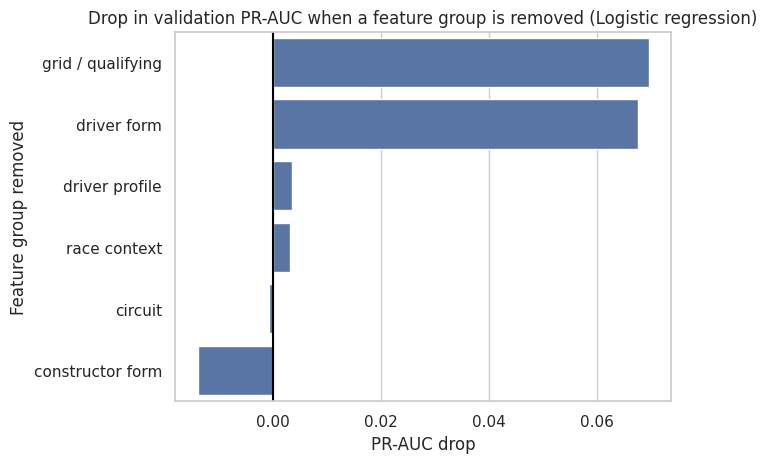

In [70]:
sns.barplot(data=ablation.sort_values('PR-AUC drop', ascending=False), x='PR-AUC drop', y='group removed')
plt.axvline(0, color='black')
plt.title(f'Drop in validation PR-AUC when a feature group is removed ({best_name})')
plt.xlabel('PR-AUC drop')
plt.ylabel('Feature group removed')
plt.show()

**What the ablation shows (logistic regression, validation 2020–2021)**
- **Grid / qualifying** and **driver form** are the two groups the model cannot do without. Removing either costs about 0.07 PR-AUC. Grid/qualifying is also the only group whose removal clearly hurts ROC-AUC (−0.040), so it carries most of the overall separation, while driver form mainly helps rank the top candidates.
- **Driver profile**, **race context** and **circuit** change PR-AUC by less than 0.004, which is noise on 759 rows. They neither help nor hurt this model.
- **Constructor form** is the surprise: removing it *raises* PR-AUC by 0.014, although Section 7.5 showed it is strongly related to podiums. The explanation is redundancy. Team strength is already reflected in the driver's grid slot and recent results, and in a linear model the extra correlated columns add noise rather than information. The effect is also within the validation uncertainty, so we keep the group for completeness rather than tune the feature set on such a small set.

This matches the pre-training evidence in 7.5 for the strong groups (grid and form), and shows that the weak context groups add little, as the near-zero correlations suggested.

## 12. Explainability (XAI)

**Important:** these explanations describe what the *model relies on* to make its predictions. They are **not causal effects**: a feature being important does not mean it causes podium finishes.

### 12.1 Global: permutation importance

We shuffle one feature at a time on the validation set and measure the drop in PR-AUC. This uses the original (un-encoded) features, so `country` is treated as one feature.

In [71]:
perm = permutation_importance(best_model, X_val, y_val, scoring='average_precision',
                              n_repeats=10, random_state=SEED)

importance = pd.DataFrame({
    'feature': features,
    'importance': perm.importances_mean,
    'std': perm.importances_std
}).sort_values('importance', ascending=False)

importance.round(4)

,feature,importance,std
0,grid_position,0.1825,0.0445
5,career_podiums,0.0563,0.0109
7,podium_rate_last_10,0.0201,0.0164
1,quali_position,0.0159,0.0217
3,career_races,0.0125,0.0055
8,wins_this_season_so_far,0.0116,0.0059
2,quali_time_gap_to_pole,0.0071,0.0103
6,avg_finish_last_5,0.0070,0.0099
15,round,0.0034,0.0062
12,driver_age_at_race,0.0032,0.0056


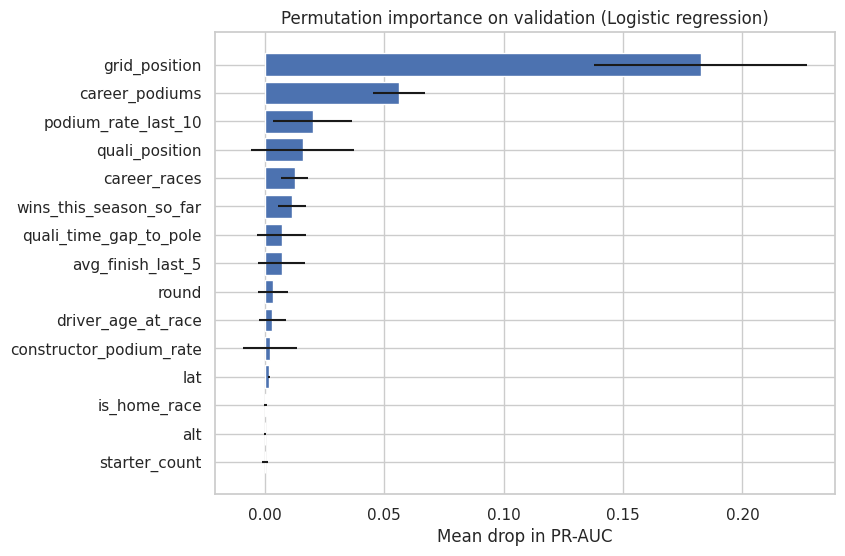

In [72]:
top = importance.head(15).sort_values('importance')

plt.figure(figsize=(8, 6))
plt.barh(top['feature'], top['importance'], xerr=top['std'])
plt.title(f'Permutation importance on validation ({best_name})')
plt.xlabel('Mean drop in PR-AUC')
plt.show()

**Interpretation.** `grid_position` dominates: shuffling it costs 0.18 PR-AUC, more than three times any other feature. Next come `career_podiums` (0.056) and `podium_rate_last_10` (0.020), the driver-form signals. `quali_position` (0.016) matters less than its strong correlation would suggest, because it overlaps heavily with the grid. When one of them is shuffled, the other still carries most of the information.

Several features have importance near zero or slightly negative (`career_wins`, `constructor_wins_this_season`, `country`, `year`). This does **not** mean they are unrelated to podiums; Section 7.5 shows that several are. It means the model gets the same information from correlated features (for example `career_podiums` instead of `career_wins`). The error bars on these features cross zero, so their ranking is not meaningful.

### 12.2 Global: SHAP

SHAP works on the model's actual inputs, i.e. the encoded and scaled matrix. We use the model-agnostic permutation explainer, so the same code works for any of the three models: 50 training rows as the background and 100 validation rows to explain.

In [73]:
preprocessor = best_model.named_steps['prep']
classifier = best_model.named_steps['model']

feature_names = [name.replace('numeric__', '').replace('category__', '')
                 for name in preprocessor.get_feature_names_out()]

X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)


def predict_podium_processed(X_processed):
    return classifier.predict_proba(X_processed)[:, 1]


background = shap.sample(X_train_processed, 50, random_state=SEED)
explainer = shap.Explainer(predict_podium_processed, background,
                           algorithm='permutation', feature_names=feature_names)

shap_rows = shap.sample(X_val_processed, 100, random_state=SEED)
shap_values = explainer(shap_rows, max_evals=2 * len(feature_names) + 1)

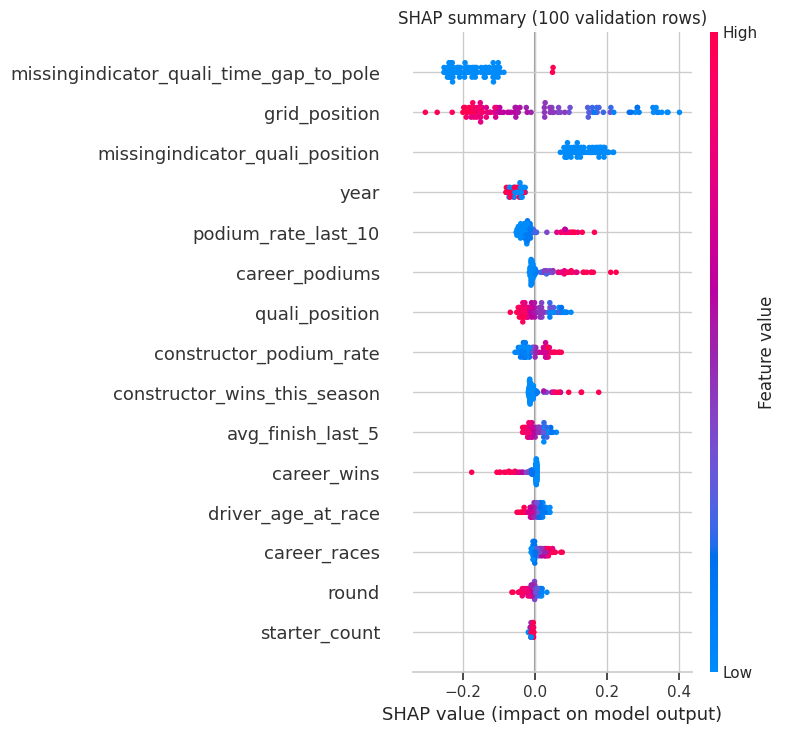

In [74]:
shap.summary_plot(shap_values.values, shap_rows, feature_names=feature_names, max_display=15, show=False)
plt.title('SHAP summary (100 validation rows)')
plt.tight_layout()
plt.show()

**Interpretation.** Each dot is one validation row. Its position shows how much a feature pushed that prediction up or down, and its colour shows the feature value (feature values are in scaled units).
- **`grid_position`:** low values (front of the grid, blue) push the podium probability up strongly, and high values (red) push it down, the expected direction.
- **Driver form:** a high `podium_rate_last_10` and many `career_podiums` (red) raise the probability, and high constructor podium rate and wins do the same in a smaller way. A worse `avg_finish_last_5` (red) lowers it.
- **The two missing-indicator columns at the top need care.** `missingindicator_quali_time_gap_to_pole` pushes predictions down, while `missingindicator_quali_position` pushes them up by a similar amount. The two columns are almost identical: both qualifying features are missing for the same rows, 58.4% vs 59.0%. Logistic regression therefore splits their shared effect into one large negative and one large positive weight that mostly cancel. They should be read **together**, as one "qualifying data present" signal with a small net effect, not as two strong independent drivers. This is a known side-effect of correlated inputs on linear-model explanations.
- **`year`** has a small negative contribution for these modern rows. The model treats later seasons as slightly harder; this reflects era differences in the training data, not a real effect of the calendar year.
- **`career_wins`** pushes *down* for drivers with many wins. This only makes sense together with `career_podiums`: the two are strongly correlated, so the model gives the positive effect to podiums and a small negative correction to wins.

Permutation importance and SHAP agree on the main story: starting position first, then recent and career driver form.

### 12.3 Local explanations: two individual predictions

We explain two validation records:
1. the podium the model was **most confident** about and got right;
2. a podium the model **missed** (a real podium finisher with a low predicted probability).

Each record is explained with both a SHAP waterfall plot and LIME.

In [75]:
best_val_prob = best_model.predict_proba(X_val)[:, 1]
best_val_pred = (best_val_prob >= thresholds[best_name]).astype(int)
actual = y_val.to_numpy()

correct_podiums = np.where((best_val_pred == 1) & (actual == 1))[0]
missed_podiums = np.where((best_val_pred == 0) & (actual == 1))[0]

record_hit = correct_podiums[np.argmax(best_val_prob[correct_podiums])]
record_miss = missed_podiums[np.argmin(best_val_prob[missed_podiums])]

drivers_by_id = clean['drivers'].set_index('driverId')
races_by_id = clean['races'].set_index('raceId')


def describe_record(position, probability):
    row = val.iloc[position]
    driver = drivers_by_id.loc[row['driverId']]
    race = races_by_id.loc[row['raceId']]
    print(f"{driver['forename']} {driver['surname']} | {race['year']} {race['name']} | "
          f"grid {row['grid_position']:.0f} | actual podium: {row['podium']} | "
          f"predicted probability: {probability:.3f}")


describe_record(record_hit, best_val_prob[record_hit])
describe_record(record_miss, best_val_prob[record_miss])

Lewis Hamilton | 2020 Bahrain Grand Prix | grid 1 | actual podium: 1 | predicted probability: 0.991
Carlos Sainz | 2021 Hungarian Grand Prix | grid 15 | actual podium: 1 | predicted probability: 0.077


In [76]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    shap.sample(X_train_processed, 1000, random_state=SEED),
    feature_names=feature_names,
    class_names=['No podium', 'Podium'],
    discretize_continuous=True,
    random_state=SEED
)

**Record 1: correct, high-confidence podium**

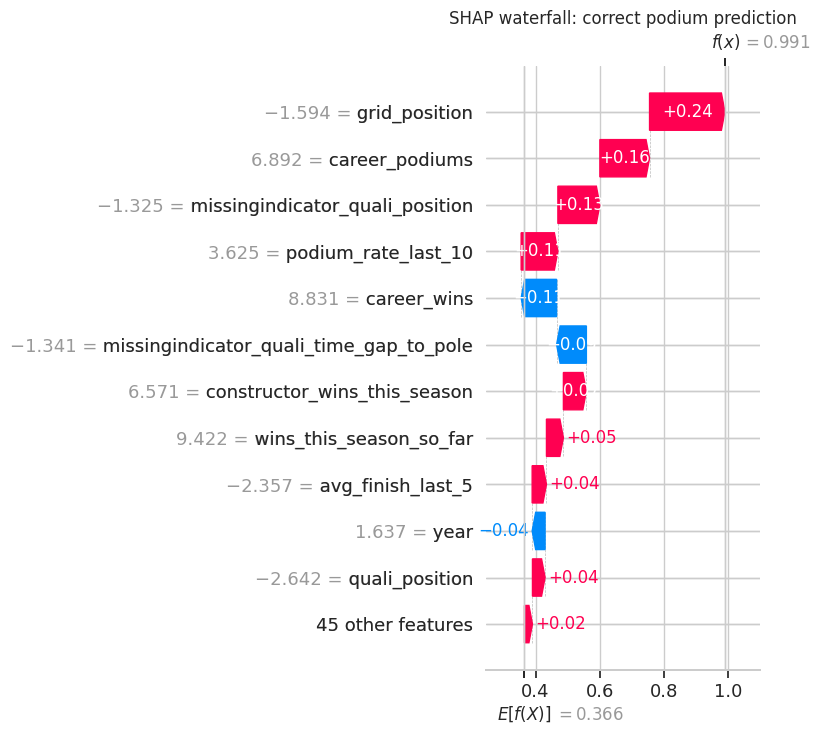

In [77]:
hit_explanation = explainer(X_val_processed[[record_hit]], max_evals=2 * len(feature_names) + 1)
shap.plots.waterfall(hit_explanation[0], max_display=12, show=False)
plt.title('SHAP waterfall: correct podium prediction')
plt.tight_layout()
plt.show()

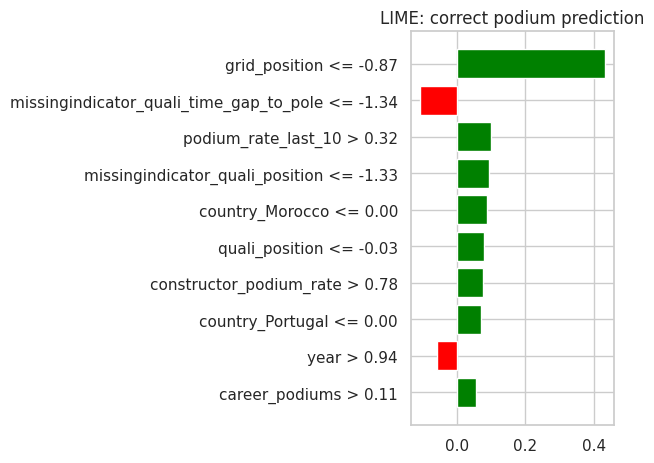

In [78]:
hit_lime = lime_explainer.explain_instance(X_val_processed[record_hit], classifier.predict_proba,
                                           num_features=10)
hit_lime.as_pyplot_figure()
plt.title('LIME: correct podium prediction')
plt.tight_layout()
plt.show()

**Interpretation (Lewis Hamilton, 2020 Bahrain GP, started 1st, finished on the podium, predicted 0.991).** Starting from a probability of 0.37 (the model's average over the background rows), SHAP shows pole position adding the most (+0.24), followed by Hamilton's very high career podium count (+0.16) and recent podium rate. LIME agrees: its largest bar is the front-row grid slot, followed by recent podium rate. Both methods tell the same story, a dominant driver starting from pole, which is exactly what we would expect. The small negative `career_wins` bar is the correlated-features correction explained above.

**Record 2: a missed podium**

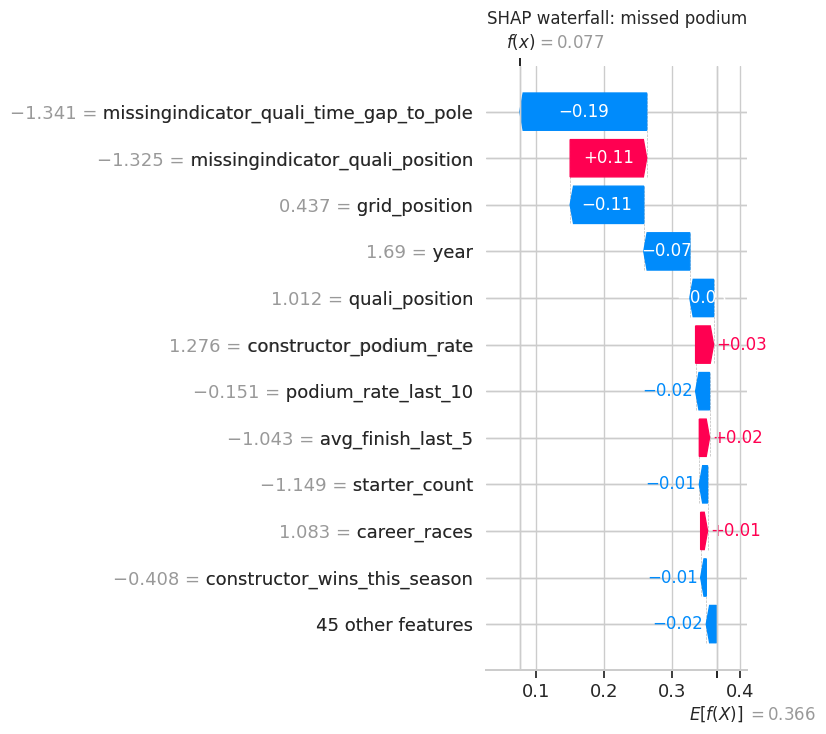

In [79]:
miss_explanation = explainer(X_val_processed[[record_miss]], max_evals=2 * len(feature_names) + 1)
shap.plots.waterfall(miss_explanation[0], max_display=12, show=False)
plt.title('SHAP waterfall: missed podium')
plt.tight_layout()
plt.show()

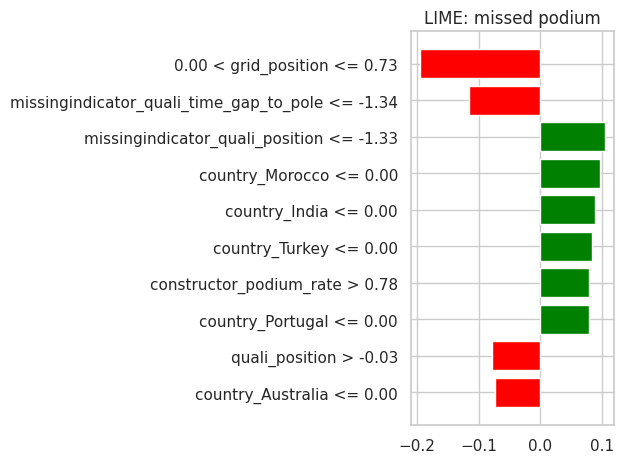

In [80]:
miss_lime = lime_explainer.explain_instance(X_val_processed[record_miss], classifier.predict_proba,
                                            num_features=10)
miss_lime.as_pyplot_figure()
plt.title('LIME: missed podium')
plt.tight_layout()
plt.show()

**Interpretation (Carlos Sainz, 2021 Hungarian GP, started 15th, finished on the podium, predicted 0.077).** Both methods put the blame on the starting position. In SHAP, apart from the paired missing-indicator columns (−0.19 and +0.11, a net of about −0.08, see the note above), grid 15 is the largest negative contribution (−0.11). In LIME it is the largest bar overall. The qualifying position and the season (`year`) push the same way. Sainz's team form (constructor podium rate) pushes slightly up, but not nearly enough. From pre-race information alone the prediction is reasonable. That race was decided by a first-lap pile-up that eliminated several front-runners, and Sainz was only promoted to third after Vettel's post-race disqualification. Neither event can be known before the start, so this "miss" shows the limit of any pre-race model rather than a flaw in this one.

**A note on LIME:** several of its bars are rules like `country_Morocco <= 0`, i.e. "this race was *not* in Morocco". These appear because LIME perturbs each one-hot column independently, which creates unrealistic rows. They carry no real meaning and should be ignored, and SHAP gives them no weight. This is why we read LIME together with SHAP rather than on its own.

## 13. Inference function

`predict_podium` takes a dictionary of pre-race features for one driver in one race and returns the podium probability from the selected model. Missing features are allowed: they become `NaN` and are filled by the imputer fitted on the training data, while the missing-value indicators tell the model they were absent.

In [81]:
def predict_podium(race_data):
    row = pd.DataFrame([{feature: race_data.get(feature, np.nan) for feature in features}])
    return float(best_model.predict_proba(row)[0, 1])

In [82]:
# a front-row starter from the test seasons, so that removing the qualifying fields has a visible effect
front_row_test = X_test[(X_test['grid_position'] <= 2) & X_test['quali_position'].notna()]
complete_record = front_row_test.iloc[0].to_dict()
dropped = ['quali_position', 'quali_time_gap_to_pole', 'avg_finish_last_5']
partial_record = {k: v for k, v in complete_record.items() if k not in dropped}

threshold = thresholds[best_name]
print('Features removed from the partial record:', dropped)
for label, record in [('Complete record', complete_record), ('Partial record', partial_record)]:
    probability = predict_podium(record)
    decision = 'podium' if probability >= threshold else 'no podium'
    print(f'{label}: probability = {probability:.3f} -> {decision} (threshold {threshold:.2f})')

Features removed from the partial record: ['quali_position', 'quali_time_gap_to_pole', 'avg_finish_last_5']
Complete record: probability = 0.953 -> podium (threshold 0.65)
Partial record: probability = 0.907 -> podium (threshold 0.65)


**Result.** For a front-row starter from the test seasons, the complete record gives a podium probability of 0.953. Removing the qualifying position, the gap to pole and the recent average finish lowers it to 0.907. With less information the model is a little less certain, but the prediction stays "podium" because the grid slot and the career form features are still there. The function returns a valid probability in both cases, with no errors for the missing fields.

## 14. Limitations

- **Qualifying coverage drift:** qualifying data is missing before 1994 and patchy until 2002, so for most training rows the qualifying features are imputed. The model leans on `grid_position` for older races.
- **Era sensitivity:** car performance, field sizes, points systems and reliability changed a lot across 75 seasons. Training mostly on older eras and testing on 2022–2024 measures performance under drift.
- **Small validation set:** 2020–2021 contains only two (COVID-affected) seasons, so validation scores, and the model choice based on them, are noisy.
- **Population:** pit-lane starters have `grid = 0` and are excluded from the modelling table together with non-starters. Rows marked `E` (excluded) are also dropped, although an exclusion can occasionally be decided after the race.
- **Team identity:** rebranded constructors get new IDs, which resets their form features.
- **Home-race mapping:** nationalities that could not be mapped to a circuit country are treated as "not home".
- **Explanations are not causal** (Section 12).